# SoyaAI: forecasting India's soybean oil imports and the Indore soybean oil rate

**Final-year AI project. ARIMAX / SARIMAX time-series forecasting.**

| | Model A (monthly) | Model B (daily) |
|---|---|---|
| Target | India's imports of soybean oil, HS 1507, tonnes per month | SOPA refined soybean oil rate, Indore, Rs per 10 kg |
| Source | UN Comtrade, Jan 2011 to Aug 2026 | SOPA, Jan 2011 to Oct 2026 (modelled from Jun 2020) |
| Model family | SARIMA / SARIMAX, s = 12 | ARIMA / ARIMAX (no weekly season, see section 3) |
| Forecast | next 12 months, 95% interval | next 30 trading days, 95% interval |

**The link between the two models:** the monthly average of Model B's target (the domestic oil rate) enters Model A as a lagged exogenous variable. On its own (`oil_rate`) and as part of an *import margin* (domestic price vs landed import cost). Section 6 tests whether it improves Model A.

### How to read this notebook
Every step has a short **Why?** box. These are the arguments to use in the viva. The code lives in reusable modules in `src/`:

| module | what it does |
|---|---|
| `src/data.py` | load and clean Comtrade and SOPA files |
| `src/features.py` | duty series, event dummies, market data, lags, leak-free exogenous matrix |
| `src/models.py` | Naive, Seasonal naive, ETS, SARIMA/SARIMAX with one interface; auto_arima; AIC/BIC grid |
| `src/evaluate.py` | rolling-origin backtest, MAE/RMSE/MASE/sMAPE, Diebold-Mariano, diagnostics |
| `src/plots.py` | all figures (saved to `outputs/figures`) |
| `src/experiments.py` | the two-stage model comparison used here and in the Streamlit app |

All settings (target HS code, lags, horizons, dates) are in `config.yaml`.

## 0. Setup and reproducibility

**Why?** Results must be repeatable by the examiner. So we (1) fix the random seed, (2) print the package versions (pinned in `requirements.txt`), and (3) read every choice from `config.yaml` instead of hard-coding it. SARIMAX fitting is deterministic. The seed matters only for `auto_arima`'s internal random steps.

The notebook also runs on Google Colab: upload the project folder to Drive and run the first cell. It installs the requirements and switches to the project folder.

In [1]:
import os, sys, random, warnings
from pathlib import Path

if "google.colab" in sys.modules:                      # optional: Colab support
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/SoyaAI")          # <- change if you put it elsewhere
    !pip -q install -r requirements.txt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels, pmdarima, scipy
from statsmodels.tsa.seasonal import STL
from scipy import stats

from src import data as D, features as F, models as M, evaluate as E, plots as P
from src import experiments as X, pipeline

cfg = D.load_config()
SEED = cfg["seed"]
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")
TAB = D.p(cfg["paths"]["tables"]); TAB.mkdir(parents=True, exist_ok=True)
FCD = D.p(cfg["paths"]["forecasts"]); FCD.mkdir(parents=True, exist_ok=True)
print(f"python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"statsmodels {statsmodels.__version__} | pmdarima {pmdarima.__version__} | scipy {scipy.__version__}")
print("project root:", ROOT)

python 3.11.9 | numpy 2.4.6 | pandas 3.1.1 | statsmodels 0.15.0 | pmdarima 2.1.1 | scipy 1.17.1
project root: C:\Users\DELL\OneDrive\Desktop\SoyaAI


## 1. Step 0: inspect the raw data before modelling

**Why?** A forecasting model cannot fix bad input. Before modelling we confirm what each file really contains: frequency, codes, units, duplicates, gaps. Otherwise we could, for example, double-count aggregate and partner rows, or read missing months as zero trade.

### 1.1 UN Comtrade import files

In [2]:
R = pipeline.build_all(cfg)          # loads, cleans and saves everything to data/processed
for hs in ["1507", "1201"]:
    print(f"--- HS {hs} ---")
    for k, v in D.check_comtrade(R[f"comtrade_raw_{hs}"]).items():
        print(f"  {k:24s} {v}")

market data: loaded from cache market_daily.csv (4149 rows)
--- HS 1507 ---
  rows                     188
  files                    16
  hs_codes                 [1507]
  frequency                ['M']
  reporters                ['India']
  flows                    ['Import']
  partners                 ['World']
  partner2                 ['World']
  customs                  ['TOTAL CPC']
  transport                ['TOTAL MOT']
  duplicate_periods        0
  first_period             201101
  last_period              202608
  estimated_weight_rows    24
--- HS 1201 ---
  rows                     149
  files                    16
  hs_codes                 [1201]
  frequency                ['M']
  reporters                ['India']
  flows                    ['Import']
  partners                 ['World']
  partner2                 ['World']
  customs                  ['TOTAL CPC']
  transport                ['TOTAL MOT']
  duplicate_periods        0
  first_period             201110


**What the checks confirm**

* **Frequency is monthly (`M`)**, so SARIMAX with s = 12 is possible. We did not have to stop because of annual-only data.
* **HS codes:** the `comtrade_1507` folder has only **1507 (soybean oil and its fractions)**, and `comtrade_1201` has only **1201 (soybean seed)**.
* **Every row is already Reporter = India, Flow = Import, Partner = World, customs = TOTAL CPC, transport = TOTAL MOT.** There are no partner-country or transport/customs breakdown rows, so double counting is impossible. `clean_comtrade` still applies these filters explicitly and raises an error if a month appears twice.
* **No duplicate months** across the yearly files.

**Cleaning rules** (in `src/data.py::clean_comtrade`):
1. **A missing month means zero trade.** Comtrade does not publish rows for months with no imports.
2. **Positive value but zero or blank weight means a missing weight, not zero trade.** We impute `tonnes = value / average USD-per-kg of the 2 months on each side`.
3. **Months after Aug 2026 are not published yet.** Comtrade releases whole months, so there is no half-filled trailing month. Sep–Dec 2026 are dropped, **not** set to zero.
4. Units: `netWgt` kg / 1000 = **tonnes**; `primaryValue` = CIF **USD**; unit price = USD per kg.

In [3]:
imp = R["imports_1507"]
print("Months with an imputed weight (HS 1507):")
display(imp[imp.weight_imputed][["value_usd", "tonnes", "usd_per_kg"]])
print("Months whose unit price is >20% away from neighbours (flagged, NOT changed):")
display(imp[imp.unit_price_outlier][["value_usd", "tonnes", "usd_per_kg", "weight_estimated_by_comtrade"]])
annual = pd.DataFrame({
    "HS1507 tonnes": R["imports_1507"].tonnes.groupby(lambda d: d.year).sum(),
    "HS1507 zero months": R["imports_1507"].tonnes.eq(0).groupby(lambda d: d.year).sum(),
    "HS1201 tonnes": R["imports_1201"].tonnes.groupby(lambda d: d.year).sum(),
    "HS1201 zero months": R["imports_1201"].tonnes.eq(0).groupby(lambda d: d.year).sum()})
annual.index.name = "year"; annual.loc[2026, :] = annual.loc[2026, :]   # 2026 = Jan-Aug only
display(annual.round(0))

Months with an imputed weight (HS 1507):


,value_usd,tonnes,usd_per_kg
month,,,
2022-07-01,8.466e+08,5.101e+05,1.66
2025-07-01,6.598e+08,5.83e+05,1.132


Months whose unit price is >20% away from neighbours (flagged, NOT changed):


,value_usd,tonnes,usd_per_kg,weight_estimated_by_comtrade
month,,,,
2021-10-01,4.603e+08,4.133e+05,1.114,True


,HS1507 tonnes,HS1507 zero months,HS1201 tonnes,HS1201 zero months
year,,,,
2011,9.394e+05,0,121,11
2012,1.089e+06,0,837,8
2013,1.108e+06,0,750,7
2014,2.106e+06,0,"3,876",7
2015,3.509e+06,0,1.338e+04,1
2016,3.893e+06,0,6.362e+04,0
2017,3.339e+06,0,7.775e+04,0
2018,2.971e+06,0,1.612e+05,1
2019,3.185e+06,0,2.295e+05,0


**Findings**
* **HS 1507 (oil):** all 188 months present. Two months had a value but no weight: **Jul 2022** and **Jul 2025**. They are imputed at about 510 thousand and 583 thousand tonnes, both plausible for July, a peak import month. **Oct 2021** has a Comtrade-*estimated* weight that implies 1.11 USD/kg while its neighbours are about 1.45, so the weight is probably too high. We keep it but flag it. Its effect on the model is visible as one large residual.
* **HS 1201 (seed): this is the "known risk" from the brief.** 39 of 188 months are zero. Imports were almost nothing in 2011–15, about 0.5 million tonnes a year in 2020–24, nearly zero in 2025 and then about 1 million tonnes in Jan–Aug 2026. A SARIMAX model cannot learn a stable pattern from these regime switches. **So the main target is HS 1507**, which India imports at 3–5 million tonnes a year and which is never near zero. HS 1201 stays available through `config.yaml` (`target_hs: "1201"`, `transform: log1p`).

### 1.2 SOPA daily soybean oil rate

In [4]:
raw = R["sopa_raw"]
print("columns:", list(pd.read_excel(D.p(cfg['paths']['raw_sopa'])).columns))
print("rows:", len(raw), "| date range:", raw.date.min().date(), "->", raw.date.max().date(),
      "| duplicate dates:", raw.date.duplicated().sum())
print("unparsable rates:", raw[["low", "high"]].isna().any(axis=1).sum(),
      "| ranges written high-low (reversed):", raw.reversed.sum(),
      "| station values:", raw.station.value_counts().to_dict())
gaps = raw.date.diff().dt.days
print("gap length in calendar days (count):", gaps.value_counts().sort_index().to_dict())
print("gaps of 3 weeks or more:")
display(pd.DataFrame({"gap_ends": raw.date[gaps >= 21].dt.date, "days": gaps[gaps >= 21]}))
print("observations by weekday (0=Mon):", raw.date.dt.dayofweek.value_counts().sort_index().to_dict())
display(raw.head(3)); display(raw.tail(3))

columns: ['Date', 'Soy Oil (Refined oil)', 'Station']
rows: 3795 | date range: 2011-01-03 -> 2026-10-31 | duplicate dates: 0
unparsable rates: 0 | ranges written high-low (reversed): 1087 | station values: {'Indore': 2701, 'indore': 1091, 'Select Station': 2, '(blank)': 1}
gap length in calendar days (count): {1.0: 2949, 2.0: 377, 3.0: 367, 4.0: 62, 5.0: 17, 6.0: 6, 7.0: 4, 8.0: 2, 10.0: 2, 11.0: 1, 12.0: 2, 23.0: 1, 28.0: 1, 74.0: 1, 144.0: 1, 239.0: 1}
gaps of 3 weeks or more:


,gap_ends,days
1091,2016-01-05,239
1092,2016-01-28,23
1093,2016-06-20,144
1094,2016-07-18,28
1990,2020-06-03,74


observations by weekday (0=Mon): {0: 696, 1: 708, 2: 707, 3: 703, 4: 665, 5: 315, 6: 1}


,date,rate_text,station,reversed,low,high,spread,mid
0,2011-01-03,605.00 - 593.00,indore,True,593,605,12,599
1,2011-01-04,603.00 - 592.00,indore,True,592,603,11,597.5
2,2011-01-05,600.00 - 590.00,indore,True,590,600,10,595


,date,rate_text,station,reversed,low,high,spread,mid
3792,2026-10-29,1410.00 - 1415.00,Indore,False,"1,410","1,415",5,"1,412"
3793,2026-10-30,1415.00 - 1418.00,Indore,False,"1,415","1,418",3,"1,416"
3794,2026-10-31,1415.00 - 1418.00,Indore,False,"1,415","1,418",3,"1,416"


**Unit check (verified, not assumed).** The file has no unit column. SOPA's website quotes the Indore refined oil rate in **Rs per 10 kg**. We matched four dates in this file exactly to quotes SOPA published: 01-Apr-2026 (1560–1565), 25-Apr-2026 (1470–1480), 31-Jul-2025 (1215–1220) and 15-Sep-2025 (1250–1255). The values (Rs 600–1,630) are also only plausible as Rs/10 kg, i.e. Rs 60–163 per kg. Rs/kg or Rs/quintal would be absurd.

**Only one rate column exists: refined soybean oil.** There is no seed or meal rate, so those cannot be exogenous variables.

**Quality issues and the rule for each** (`src/data.py`):

| issue | rule |
|---|---|
| 1,087 ranges written "high - low" (2011 to May 2015) | take min and max, use the **midpoint** |
| one-day wide ranges (> Rs 50), e.g. 24-Jan-2019 "667–770" | isolated → use the end closer to the 11-day median (a typo); runs of wide ranges (June 2013) are kept |
| isolated spikes > 8% from the 11-day median that revert next day (05-Jan-2016, 13-Dec-2016) | set to **missing** |
| 3 rows with station "Select Station"/blank (2025) | website glitch; values fine, kept |
| 239-day gap (2015–16), 144-day gap (2016), 74-day gap (COVID lockdown, Mar–Jun 2020) | **Model B starts on 17-Jun-2020**, after the last long gap |
| Saturdays quoted on only 315 of ~820 weeks | business-day (Mon–Fri) calendar; a Saturday quote can fill a Monday holiday |

In [5]:
s = R["sopa_clean"]
fixes = s[s.fix_wide_range | s.fix_spike_removed][["rate_text", "mid", "rate", "fix_wide_range", "fix_spike_removed"]]
display(fixes)
mb = cfg["model_b"]
w = R["sopa_bday_full"].loc[mb["start"]:mb["end"]]
print(f"Model B window {mb['start']} -> {mb['end']}: {len(w)} business days | quoted {w.observed.notna().sum()} | "
      f"holiday-filled (<= {mb['ffill_limit']} days) {w.filled.sum()} | left missing {w.rate.isna().sum()}")
print("missing days that remain:", list(w.index[w.rate.isna()].date))

,rate_text,mid,rate,fix_wide_range,fix_spike_removed
date,,,,,
2013-11-13,695.00 - 643.00,669,695,True,False
2016-01-05,735.00 - 737.00,736,NaN,False,True
2016-12-13,625.00 - 630.00,627.5,NaN,False,True
2019-01-24,667.00 - 770.00,718.5,770,True,False
2020-12-24,1040.00 - 1145.00,"1,092","1,145",True,False


Model B window 2020-06-17 -> 2026-10-31: 1663 business days | quoted 1546 | holiday-filled (<= 3 days) 110 | left missing 7
missing days that remain: [datetime.date(2020, 9, 29), datetime.date(2020, 9, 30), datetime.date(2020, 11, 17), datetime.date(2020, 11, 18), datetime.date(2020, 11, 19), datetime.date(2020, 11, 20), datetime.date(2021, 11, 8)]


**Why a business-day calendar with a 3-day forward-fill limit?**
* ARIMA needs **equally spaced** observations. Mon–Fri is the standard trading calendar. Saturdays are quoted irregularly, so a Mon–Sat grid would be mostly filled-in values.
* A holiday has no new price, so carrying the last price forward is the market's own convention. We allow at most **3 business days**, enough for normal holidays and Diwali.
* **Longer gaps stay missing** (7 days). statsmodels' SARIMAX uses the **Kalman filter**, which simply skips missing observations in the likelihood. That is more honest than inventing a week of prices.

**Monthly alignment for the link:** the monthly oil rate is the mean of the days quoted in that calendar month, labelled by month start, which is the same label as the Comtrade import month.

### 1.3 Summary of Step 0: assumptions we proceed with
1. Main target for Model A: **HS 1507 tonnes**. HS 1201 is too irregular (39 zero months, regime switches) but is still configurable.
2. Missing Comtrade months = zero trade. Two missing weights imputed from unit value. Sep–Dec 2026 are unknown, not zero.
3. SOPA unit = Rs/10 kg (verified). Midpoint of the range. Typos fixed by the two rules above.
4. Model B uses 17-Jun-2020 to 30-Oct-2026 on a Mon–Fri calendar.
5. Exogenous data: USD/INR, Brent and CBOT soybean oil from Yahoo Finance (downloaded once, cached in `data/raw/external/market_daily.csv`). An **effective-duty table** on crude soybean oil with a source for every row (`data/raw/external/duty_events_crude_soyoil.csv`). COVID-lockdown and Ukraine-war dummies.

In [6]:
ev = R["duty_events"]
display(ev[["effective_from", "basic_duty_pct", "aidc_pct", "effective_duty_pct", "event", "confidence"]])

,effective_from,basic_duty_pct,aidc_pct,effective_duty_pct,event,confidence
0,2011-01-01,0,0,0,Nil duty on crude edible oils (in force since ...,high
1,2013-01-23,2.5,0,2.575,Duty of 2.5% levied on crude edible oils,high
2,2014-12-24,7.5,0,7.725,Crude edible oils raised to 7.5% (refined 15%),high
3,2015-09-17,12.5,0,12.88,Notification 46/2015-Customs: crude 7.5 -> 12.5%,high
4,2017-08-11,17.5,0,18.02,Crude soybean oil raised to 17.5%,medium
5,2017-11-17,30,0,30.9,Notification 87/2017-Customs: crude soy 17.5 -...,high
6,2018-02-02,30,0,33,Budget 2018: 10% Social Welfare Surcharge repl...,medium
7,2018-06-14,35,0,38.5,Notification 47/2018-Customs: crude soy 30 -> ...,high
8,2021-02-02,15,20,38.5,Budget 2021: basic 35 -> 15% plus 20% AIDC (ef...,high
9,2021-08-20,7.5,20,30.25,Basic duty on crude soy 15 -> 7.5%,high


**Why an effective-duty *level* instead of one dummy per duty change?** 13 changes would need 13 dummies (13 parameters from about 180 months, which invites over-fitting). One continuous variable, "effective duty %" (basic duty + agri cess + 10% social-welfare surcharge), uses one parameter with a clear meaning. The dates were checked against government notifications and news reports (sources in the CSV). Several are visible as same-day jumps in the SOPA price: +12% on 20-Nov-2017, +10% on 16-Sep-2024, −6% on 14-Oct-2021, −3% on 31-May-2025. The Sep-2026 cut (24-Sep-2026, crude soy basic duty 10% → 5%) was preceded by a gradual fall, which suggests the market expected it.

## 2. Exploratory data analysis

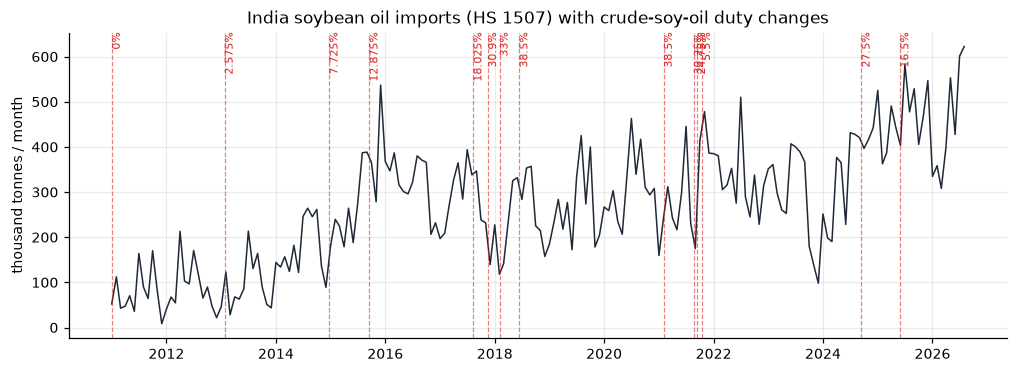

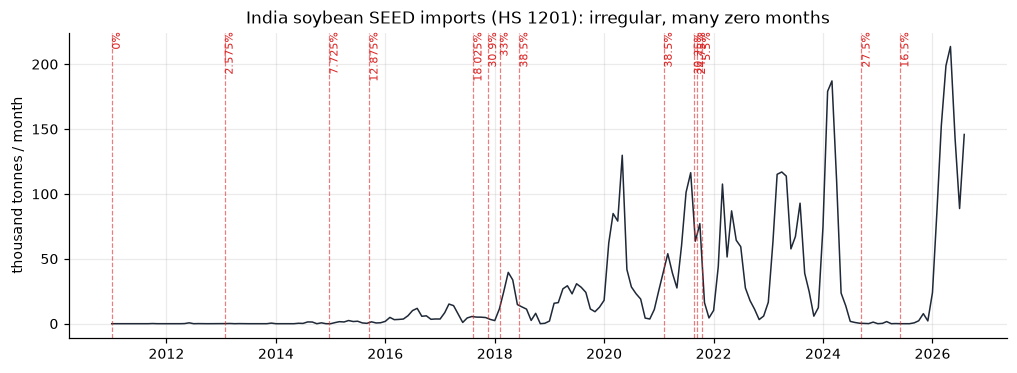

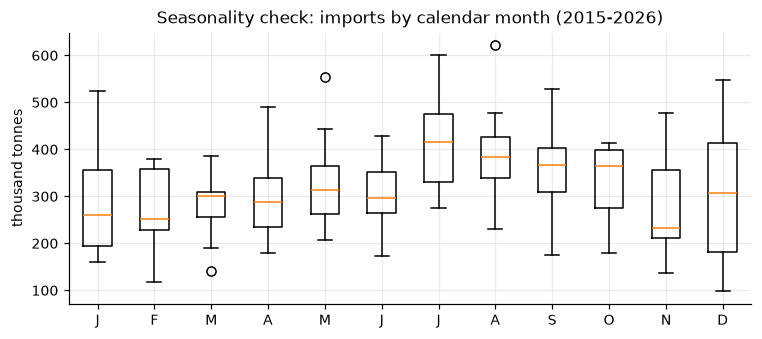

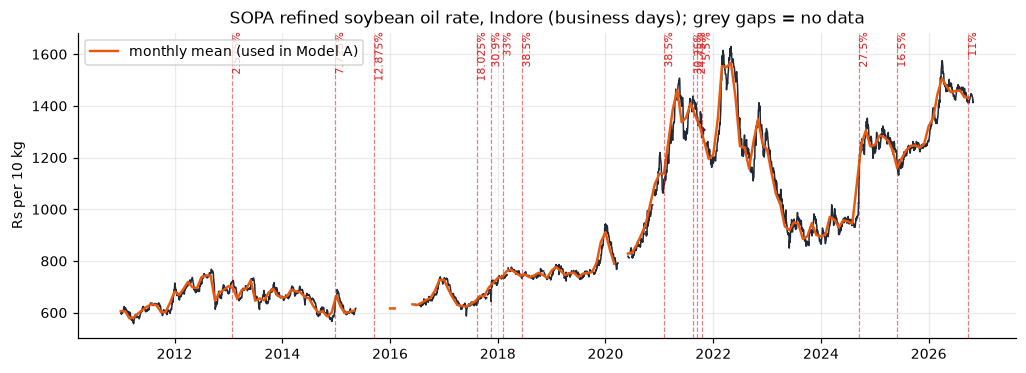

In [7]:
m = R["monthly"].loc[cfg["model_a"]["start"]:cfg["model_a"]["end"]]
P.series_with_events(m.tonnes / 1e3, ev, "India soybean oil imports (HS 1507) with crude-soy-oil duty changes",
                     "thousand tonnes / month", "01_imports_1507");
P.series_with_events(R["imports_1201"].tonnes / 1e3, ev, "India soybean SEED imports (HS 1201): irregular, many zero months",
                     "thousand tonnes / month", "02_imports_1201");
P.month_profile(m.tonnes.loc["2015":] / 1e3, "Seasonality check: imports by calendar month (2015-2026)", "thousand tonnes", "03_month_profile");
d = R["daily"]
P.series_with_events(d.rate.loc["2011":], ev, "SOPA refined soybean oil rate, Indore (business days); grey gaps = no data",
                     "Rs per 10 kg", "04_sopa_daily", extra=D.monthly_mean(d.rate), extra_label="monthly mean (used in Model A)");
plt.show()

**What the plots show**
* **Imports grew in two steps:** about 1 Mt/yr in 2011–13 → about 3.5 Mt/yr from 2015 → about 5.6 Mt in 2025 (with the imputed July). The 2014–15 jump is a level shift. Section 7 tests for a structural break. Differencing (d = 1) absorbs such level shifts.
* **Clear seasonality:** imports are high in **Jul–Oct** (before the domestic kharif soybean crush starts) and low in **Nov–Dec** (fresh domestic crushing). That justifies a seasonal model with s = 12.
* Does the **spread grow with the level**? If yes, a log transform is needed. Section 3 tests this instead of assuming it.
* **HS 1201** confirms the known risk: long zero runs and switches between regimes.
* **The oil rate** trends up with big episodes: the 2021–22 global veg-oil spike, the 2023 fall, and duty-driven jumps.
* **Zero-import months for HS 1507: none**, so even a log transform would be safe (no `log1p` needed).

## 3. Stationarity, transformation and seasonality: choosing log, d, D, s

**Why?** ARIMA assumes that after differencing the series has a constant mean and variance. We use **two tests with opposite null hypotheses**, because each alone can mislead:
* **ADF** H0: unit root (non-stationary). A small p-value means stationary.
* **KPSS** H0: stationary. A small p-value means non-stationary.

We call a series stationary only when both agree.

Box-Cox lambda (max. likelihood): full 0.76, 2015+ 0.52
Guerrero lambda (variance stabilising): full 0.70, 2015+ 1.00
   (lambda = 0 means log, lambda = 1 means no transform)


month,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
mean (kt),78.28,90.71,92.32,175.5,292.4,324.4,278.2,247.6,265.4,311.6,300.2,328.4,291.9,345.6,468.6,450.7
sd (kt),49.49,55.62,55.65,62.42,107.9,58.18,77.47,83.11,84.35,72.24,107.4,74.87,106.5,98.44,69.63,124.3
sd/mean,0.63,0.61,0.6,0.36,0.37,0.18,0.28,0.34,0.32,0.23,0.36,0.23,0.36,0.28,0.15,0.28


MASE                   sMAPE                  
h            1     3     6     12    1     3     6     12
transform                                                
log       1.097 1.219 1.482 1.491 26.44  29.1 34.91 35.27
none      0.966  1.05 1.177   1.2 23.32 24.84 27.77 28.23

config transform for Model A: none


,n,ADF_stat,ADF_p,KPSS_stat,KPSS_p,verdict
series,,,,,,
kt,188,-0.8332,0.8092,1.567,0.01,non-stationary
Δ kt (d=1),187,-7.754,9.862e-12,0.0503,0.1,stationary
Δ12 kt (D=1),176,-3.362,0.01233,0.08139,0.1,stationary
"Δ Δ12 kt (d=1,D=1)",175,-5.71,7.334e-07,0.01724,0.1,stationary


STL strength: seasonal 0.37, trend 0.77  (0 = none, 1 = very strong)


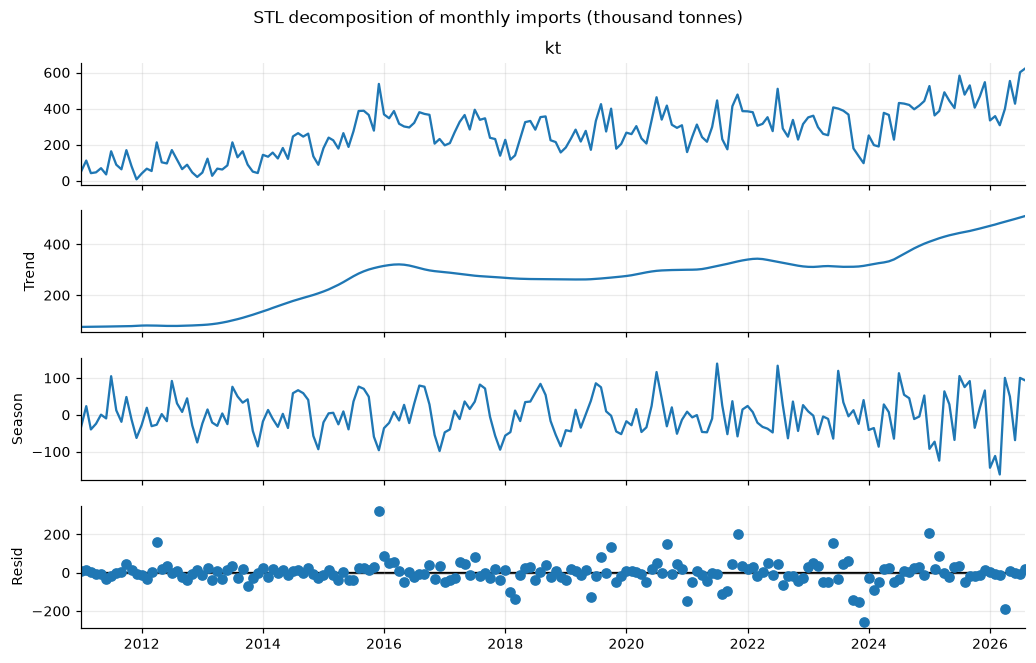

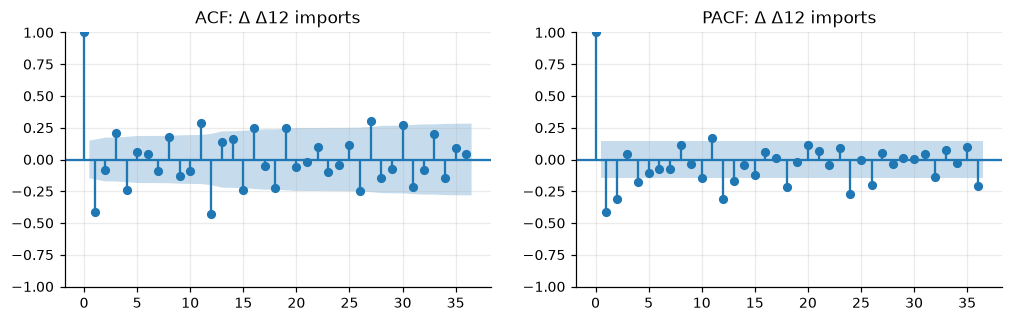

In [8]:
def guerrero(x, period=12, grid=np.linspace(-1, 2, 61)):
    # Guerrero (1993): the lambda that makes sd / mean^(1-lambda) most constant across years
    n = len(x) // period * period
    b = x.values[-n:].reshape(-1, period); mu, sd = b.mean(1), b.std(1, ddof=1)
    cv = [np.std(sd / mu ** (1 - l)) / np.mean(sd / mu ** (1 - l)) for l in grid]
    return grid[int(np.argmin(cv))]

print(f"Box-Cox lambda (max. likelihood): full {stats.boxcox(m.tonnes)[1]:.2f}, 2015+ {stats.boxcox(m.tonnes['2015':])[1]:.2f}")
print(f"Guerrero lambda (variance stabilising): full {guerrero(m.tonnes):.2f}, 2015+ {guerrero(m.tonnes['2015':]):.2f}")
print("   (lambda = 0 means log, lambda = 1 means no transform)")
yr = m.tonnes.groupby(m.index.year)
display(pd.DataFrame({"mean (kt)": yr.mean() / 1e3, "sd (kt)": yr.std() / 1e3, "sd/mean": yr.std() / yr.mean()}).round(2).T)

# Decide by forecast accuracy: same SARIMA, same backtest, log vs no transform
yy = X.target_a(cfg, R["monthly"])
orig = list(range(cfg["model_a"]["cv_initial_months"] - 1, len(yy) - 1))
mk = {"SARIMA(0,1,1)(0,1,1)12": lambda: M.Sarimax((0, 1, 1), (0, 1, 1, 12))}
tr_cmp = pd.concat([E.summarize(E.rolling_origin(yy, mk, orig, 12, tr, 12), cfg["model_a"]["horizons"]).assign(transform=tr)
                    for tr in ["log", "none"]])
display(tr_cmp.pivot_table(index="transform", columns="h", values=["MASE", "sMAPE"]).round(3))
tr_cmp.to_csv(TAB / "transform_comparison_model_a.csv", index=False)
print("config transform for Model A:", cfg["model_a"]["transform"])

y_a = E.FWD[cfg["model_a"]["transform"]](X.target_a(cfg, R["monthly"]))   # thousand tonnes (kt)
tab_a = E.stationarity_table({"kt": y_a, "Δ kt (d=1)": y_a.diff(),
                              "Δ12 kt (D=1)": y_a.diff(12), "Δ Δ12 kt (d=1,D=1)": y_a.diff().diff(12)})
display(tab_a)
stl_a = STL(y_a, period=12, robust=True).fit()
Fs = max(0, 1 - np.var(stl_a.resid) / np.var(stl_a.seasonal + stl_a.resid))
Ft = max(0, 1 - np.var(stl_a.resid) / np.var(stl_a.trend + stl_a.resid))
print(f"STL strength: seasonal {Fs:.2f}, trend {Ft:.2f}  (0 = none, 1 = very strong)")
P.stl_plot(stl_a, "STL decomposition of monthly imports (thousand tonnes)", "05_stl_imports")
P.acf_pacf(y_a.diff().diff(12), 36, "Δ Δ12 imports", "06_acf_imports");
plt.show()

**Decisions for Model A (read from the output above)**
* **Transform: none (λ = 1). We tested our own first assumption and the data rejected it.** We expected a log transform, the usual choice for trade volumes. But:
  1. Guerrero's variance-stabilising λ is about 1 for 2015 onwards. Once imports reached about 3 Mt/yr, the size of the monthly swings (sd ≈ 70–125 kt) no longer grows with the level (sd/mean actually falls).
  2. The Box-Cox maximum-likelihood λ is about 0.5–0.75, between log and none. It targets normality, not forecast accuracy.
  3. **The backtest decides:** the same SARIMA is clearly more accurate on the original scale at every horizon. One reason: `exp(log forecast)` is the **median**, which systematically under-forecasts the mean of a skewed series.

  So Model A works directly in **thousand tonnes (kt)**. `config.yaml` (`transform`) can switch back to `log`, and the comparison table is saved. (Thousand tonnes rather than tonnes is purely numerical: values of about 100–600 keep the optimiser stable, while raw tonnes of about 10⁵ gave slightly different AIC rankings.)
* **d = 1.** The import level is non-stationary (ADF p ≈ 0.8, KPSS p ≈ 0.01). After one difference both tests agree on stationary.
* **s = 12, and D (seasonal differencing) is tested separately below.** STL shows a clear seasonal component with a stable Jul–Oct peak. After d = 1 and D = 1 the remaining ACF has a negative spike at lag 1 (≈ −0.42) and at lag 12 (≈ −0.43). That is the textbook signature of **MA(1) × seasonal MA(1)**, the "airline" model (0,1,1)(0,1,1)₁₂, our starting candidate.

### 3.1 Is seasonal differencing (D = 1) really needed?
**Why a separate test?** ADF and KPSS test for a unit root at lag 1, not at the seasonal lag 12. The tests for a *seasonal* unit root are **OCSB** (Osborn–Chui–Smith–Birchenhall) and **Canova–Hansen**. A related warning sign: if D = 1 is too much, the fitted seasonal MA coefficient goes to about **−1**. The "−1" cancels the seasonal difference, which means the seasonal pattern is **deterministic** (the same calendar shape every year).

In [9]:
from pmdarima.arima import nsdiffs
print("seasonal differences suggested -> OCSB:", nsdiffs(y_a, m=12, test="ocsb"), "| Canova-Hansen:", nsdiffs(y_a, m=12, test="ch"))
for o, so in [((0, 1, 2), (0, 1, 1, 12)), ((0, 1, 2), (1, 0, 1, 12))]:
    r = M.Sarimax(o, so).fit(y_a)
    print(f"{o}{so}: seasonal coefficients", {k: round(v, 3) for k, v in r.res.params.items() if ".S." in k},
          f"AIC {r.res.aic:.1f}")
mk = {"D=1: (0,1,2)(0,1,1)12": lambda: M.Sarimax((0, 1, 2), (0, 1, 1, 12)),
      "D=0: (0,1,2)(1,0,1)12": lambda: M.Sarimax((0, 1, 2), (1, 0, 1, 12))}
d_cmp = E.summarize(E.rolling_origin(yy, mk, orig, 12, cfg["model_a"]["transform"], 12),
                    cfg["model_a"]["horizons"])
display(d_cmp.pivot_table(index="model", columns="h", values="MASE").round(3))
d_cmp.to_csv(TAB / "seasonal_differencing_comparison_model_a.csv", index=False)

seasonal differences suggested -> OCSB: 0 | Canova-Hansen: 0


(0, 1, 2)(0, 1, 1, 12): seasonal coefficients {'ma.S.L12': -0.999} AIC 2033.6


(0, 1, 2)(1, 0, 1, 12): seasonal coefficients {'ar.S.L12': 0.999, 'ma.S.L12': -0.982} AIC 2158.0


h,1,3,6,12
model,,,,
"D=0: (0,1,2)(1,0,1)12",0.953,1.03,1.166,1.175
"D=1: (0,1,2)(0,1,1)12",0.956,1.032,1.161,1.167


**Reading:** both seasonal tests say **D = 0**, yet the D = 1 model's seasonal MA is about −1. The best D = 0 model has a seasonal AR of about +1 and a seasonal MA of about −1, which almost cancel. **Every route says the same thing: the import season is nearly deterministic.** Jul–Oct is high and Nov–Dec low every year, with little random drift in that shape.

**Decision:** the two specifications give **practically identical forecasts** in the backtest, so the choice does not affect any result. We keep the D = 1 form because it is the standard, compact SARIMA for monthly trade data and our candidates were chosen on that basis. What to say in the viva: *the seasonal MA at the −1 boundary is a known symptom of deterministic seasonality, not an error. Because the parameter sits on the invertibility boundary, its standard error (and the σ² standard error) printed in section 7 is unreliable, so we judge that part of the model by the backtest instead.* An equivalent alternative would be ARIMA(0,1,2) with 11 monthly dummy variables.

,n,ADF_stat,ADF_p,KPSS_stat,KPSS_p,verdict
series,,,,,,
log rate,1656,-2.347,0.1573,0.7972,0.01,non-stationary
Δ log rate (daily return),1652,-10.99,7.016e-20,0.1361,0.1,stationary


weekly (s=5) seasonal strength of daily returns: 0.10


,mean return (bp),std (bp),n
Mon,19.2,148.9,332
Tue,-7.1,114,332
Wed,-0.4,95.6,332
Thu,1.5,104.9,333
Fri,2.9,98.2,333


ANOVA, mean return equal on all weekdays: p = 0.047


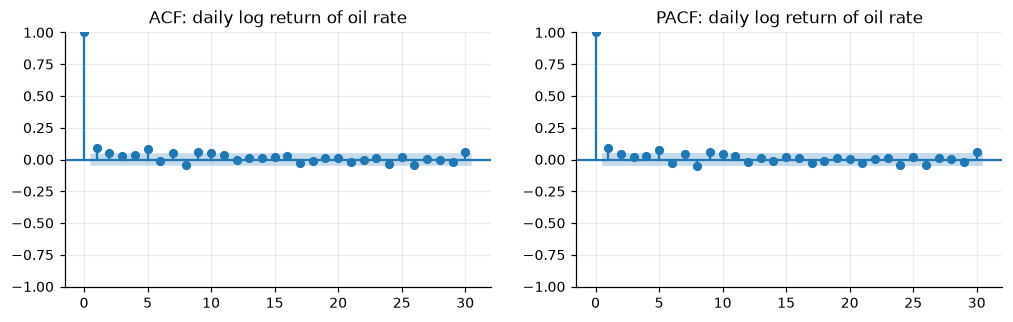

In [10]:
mb = cfg["model_b"]
yb = np.log(R["daily"].rate.loc[mb["start"]:mb["end"]])
display(E.stationarity_table({"log rate": yb, "Δ log rate (daily return)": yb.diff()}))
ret = yb.ffill().diff().dropna()
stl_b = STL(ret, period=5, robust=True).fit()
Fs5 = max(0, 1 - np.var(stl_b.resid) / np.var(stl_b.seasonal + stl_b.resid))
print(f"weekly (s=5) seasonal strength of daily returns: {Fs5:.2f}")
wd = (ret.groupby(ret.index.dayofweek).agg(["mean", "std", "count"]) * [1e4, 1e4, 1])
wd.index = ["Mon", "Tue", "Wed", "Thu", "Fri"]; wd.columns = ["mean return (bp)", "std (bp)", "n"]
display(wd.round(1))
print("ANOVA, mean return equal on all weekdays: p =", round(stats.f_oneway(*[g.values for _, g in ret.groupby(ret.index.dayofweek)]).pvalue, 3))
P.acf_pacf(ret, 30, "daily log return of oil rate", "07_acf_oil");
plt.show()

**Decisions for Model B**
* **Log, d = 1:** the log price is non-stationary and the daily return is stationary (both tests agree). Modelling log prices also makes the CBOT coefficient an **elasticity**.
* **No weekly seasonality (s = 5 rejected).** The STL weekly strength is small. A seasonal ARIMA would need a stable *repeating* weekly pattern in the level, and the ACF shows no spike at lags 5, 10, 15. The weekday means differ only borderline (ANOVA p ≈ 0.05), and the difference is driven by **Monday**. That is a **calendar effect, not a season**: Monday's change covers 3 calendar days (Saturday quotes plus weekend international news), which also explains its larger standard deviation. A seasonal ARIMA with s = 5 would model a repeating 5-day *cycle* in the price level, which does not exist. So Model B is a non-seasonal **ARIMAX**. A Monday dummy is listed as future work.
* The ACF and PACF of returns are small (lag 1 ≈ 0.09). The Indore price is close to a random walk on its own, so any gain must come from outside information. That motivates the exogenous drivers.

## 4. Exogenous variables: which drivers, at which lag, without leakage

**Economic reasoning first, then statistics:**
* **CBOT soybean oil** (world price, US cents/lb) and **Brent crude** (bio-diesel link to veg-oil prices) drive the **import-parity** price of oil in India.
* **USD/INR** converts the world price to rupees.
* **Effective import duty** adds directly to the landed cost.
* For imports (Model A), what should matter is **profitability of importing**: the domestic price relative to the landed cost. We build an **import margin**:
  $$\text{margin}_t = \log\frac{\text{Indore rate (Rs/kg)}}{\text{CBOT}\times 2.20462/100 \times \text{USD/INR} \times (1+\text{duty})}$$
  This contains Model B's target (the oil rate), so it is one way to link the models. The other is the plain lagged oil rate.

**Statistical screening** is done on *stationary* (differenced) series, because correlating two trending series gives spurious correlation:
* the **cross-correlation function (CCF)** at lag k: corr(Δy_t, Δx_{t−k});
* the **Granger test**: do past values of x improve the prediction of y beyond y's own past? (H0: no.)

,ccf0,ccf1,ccf2,ccf3,ccf4,ccf5,ccf6,granger_p1,granger_p2,granger_p3,granger_p4,granger_p5,granger_p6
driver,,,,,,,,,,,,,
oil_rate (log),-0.158,-0.042,0.163,0.023,-0,-0.002,0.042,0.183,0.022,0.047,0.129,0.29,0.342
margin,-0.158,0.081,0.058,0.152,-0.048,-0.002,-0.045,0.699,0.749,0.044,0.158,0.267,0.396
usdinr (log),-0.01,-0.034,-0.097,0.007,0.031,-0.084,0.049,0.59,0.215,0.384,0.701,0.56,0.676
brent (log),0.066,0.032,-0.067,-0.038,0.041,0.045,0.03,0.432,0.615,0.757,0.748,0.78,0.929
cbot_soyoil (log),0.045,-0.058,0.105,-0.109,-0.039,0.012,0.069,0.54,0.192,0.117,0.239,0.309,0.15
duty (%),-0.089,-0.117,0.048,0.011,0.049,-0.01,0.028,0.032,0.048,0.115,0.112,0.161,0.201


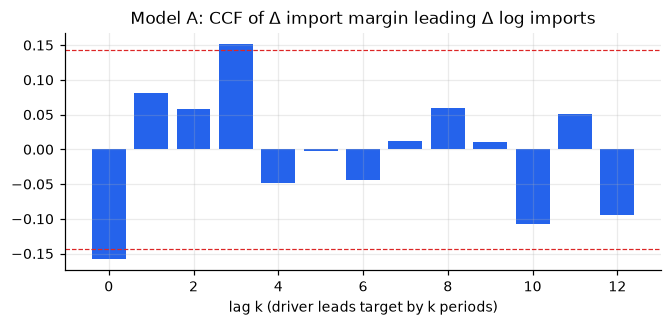

In [11]:
dy = y_a.diff()
rows = []
for c, x in {"oil_rate (log)": np.log(m.oil_rate), "margin": m.margin, "usdinr (log)": np.log(m.usdinr),
             "brent (log)": np.log(m.brent), "cbot_soyoil (log)": np.log(m.cbot_soyoil), "duty (%)": m.duty}.items():
    cc = F.ccf_table(dy, x.diff(), 6); g = F.granger_table(dy, x.diff(), 6)
    rows.append({"driver": c, **{f"ccf{k}": cc[k] for k in range(7)}, **{f"granger_p{k}": g.p_value[k] for k in range(1, 7)}})
screen_a = pd.DataFrame(rows).set_index("driver")
display(screen_a.round(3)); screen_a.to_csv(TAB / "exog_screening_model_a.csv")
P.ccf_bar(F.ccf_table(dy, m.margin.diff(), 12), len(dy), "Model A: CCF of Δ import margin leading Δ log imports", "08_ccf_margin");
plt.show()

**Model A reading**
* **Import margin:** the positive CCF peaks at **lag 3** (≈ 0.15) and the Granger test rejects "no effect" at **lag 3** (p ≈ 0.04). That fits the business: a profitable margin today → contracts → cargo arrives about 3 months later. **Chosen lag: 3.**
* **Oil rate alone:** positive CCF at **lag 2** (≈ 0.16), Granger p ≈ 0.02 at lag 2. **Chosen lag: 2.** This is the direct Model B → Model A link the project must test.
* Both lags were also confirmed on the log scale during development, so the choice does not depend on the transform.
* The negative same-month correlation (lag 0) is reverse causality: a big import month pushes the domestic price down. That is exactly why we never use lag 0 for prices.
* USD/INR, Brent, CBOT and duty **on their own** show no lead. Their effect works through the margin (their combination), not separately. So we do not add them as separate regressors, which would only add noise.
* COVID and Ukraine dummies are tested as a third exogenous set (`margin_events`).

,ccf0,ccf1,ccf2,ccf3,ccf4,ccf5,granger_p1,granger_p2,granger_p3,granger_p4,granger_p5
driver,,,,,,,,,,,
cbot_soyoil,0.182,0.439,0.049,-0.022,-0.046,0.019,0,0,0,0,0
brent,0.088,0.194,0.004,-0.002,-0.025,0.025,0,0,0,0,0
usdinr,-0.022,0.018,-0.012,0.054,-0.003,-0.028,0.412,0.658,0.122,0.219,0.206


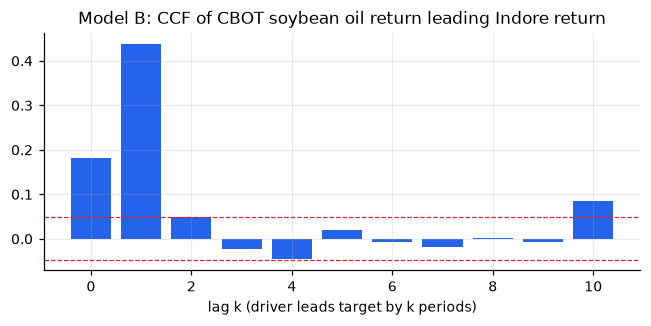

In [12]:
dly = R["daily"].loc[mb["start"]:mb["end"]]
rows = []
for c in ["cbot_soyoil", "brent", "usdinr"]:
    dx = np.log(dly[c]).diff()
    cc = F.ccf_table(yb.ffill().diff(), dx, 5); g = F.granger_table(yb.ffill().diff(), dx, 5)
    rows.append({"driver": c, **{f"ccf{k}": cc[k] for k in range(6)}, **{f"granger_p{k}": g.p_value[k] for k in range(1, 6)}})
screen_b = pd.DataFrame(rows).set_index("driver")
display(screen_b.round(3)); screen_b.to_csv(TAB / "exog_screening_model_b.csv")
P.ccf_bar(F.ccf_table(yb.ffill().diff(), np.log(dly.cbot_soyoil).diff(), 10), len(yb),
          "Model B: CCF of CBOT soybean oil return leading Indore return", "09_ccf_cbot");
plt.show()

**Model B reading.** There is a very clear **one-day lead**: yesterday's CBOT soybean-oil return correlates about 0.44 with today's Indore return, and Brent about 0.19 (Granger p < 0.001). Same-day correlation is much smaller. The reason is time zones: Chicago trades after the Indian market closes, so Indore reacts the **next** morning. USD/INR has no daily lead. **Chosen lags: CBOT 1, Brent 1** (set `cbot_brent`). A `full` set adds USD/INR, duty and the Ukraine dummy to test whether they add anything.

### 4.1 Avoiding look-ahead leakage

**Why?** If a model uses an exogenous value that would not be known at forecast time, its backtest accuracy is fake. We considered the two standard fixes and **chose (b)**:

(a) use only lags ≥ the forecast horizon. That would force CBOT to lag 20 days for the 20-day forecast, throwing away the strong 1-day signal.

(b) **forecast the exogenous variables separately.** At each forecast origin we cut every driver at the origin and fill later values with the **last known value** (a random-walk forecast, the standard benchmark for asset prices). Lagged real values are used whenever the lag reaches back before the origin. So with CBOT at lag 1 the model uses the *real* CBOT for the 1-day forecast and the *random-walk forecast* of CBOT for days 2–20, exactly what a trader would have.

How each driver is forecast after the origin depends on what kind of variable it is (`config.yaml → exog_forecast`):
* **Prices and policy** (CBOT, Brent, USD/INR, oil rate, duty): **no change.** For asset prices a random walk is the hard-to-beat benchmark. For duty, the honest assumption is "no new policy" unless we run an explicit **scenario**.
* **The import margin: its own AR(1), fitted on data up to the origin only.** The margin is a *spread*: if importing is very profitable, more cargo arrives and the margin closes. So it reverts to its mean, and "no change" for 9 months ahead would be a poor forecast. Section 6 reports both versions, so this choice is backed by evidence.
* Months with no SOPA quotes **inside** the history (2015–16, Apr–May 2020) are linearly interpolated. Both ends of such a gap are before the origin, so nothing leaks.

`features.exog_for_window` implements all of this. The cell below shows it at one origin.

In [13]:
Xa_raw = X.exog_raw_a(R["monthly"])
origin_idx = m.index[: m.index.get_loc(pd.Timestamp("2025-12-01")) + 1]
Xtr, Xfu = F.exog_for_window(Xa_raw, {"margin": 3}, origin_idx, 6, "MS", methods={"margin": "ar1"})
_, Xfu_rw = F.exog_for_window(Xa_raw, {"margin": 3}, origin_idx, 6, "MS")
demo = pd.DataFrame({"true margin 3 months earlier (unknown after Dec 2025)": Xa_raw.margin.shift(3).reindex(Xfu.index),
                     "margin_lag3 the model sees (AR(1) driver)": Xfu.margin_lag3,
                     "margin_lag3 with no-change driver": Xfu_rw.margin_lag3})
print("Origin = Dec 2025. Forecast months Jan-Jun 2026:")
display(demo)

Origin = Dec 2025. Forecast months Jan-Jun 2026:


,true margin 3 months earlier (unknown after Dec 2025),margin_lag3 the model sees (AR(1) driver),margin_lag3 with no-change driver
2026-01-01,0.08938,0.08938,0.08938
2026-02-01,0.07294,0.07294,0.07294
2026-03-01,0.08511,0.08511,0.08511
2026-04-01,0.09093,0.08909,0.08511
2026-05-01,0.004895,0.09274,0.08511
2026-06-01,-0.0788,0.0961,0.08511


For Jan–Mar 2026 the model sees the real margins of Oct–Dec 2025 (known at the origin), and all three columns agree. For Apr–Jun 2026 it needs Jan–Mar 2026 margins, which are not yet known. It gets an AR(1) forecast that drifts towards the mean, or with the no-change rule, the Dec-2025 value repeated. As a comparison only, section 6 also reports an **"oracle"** run fed the true future margin. The gap between the two shows how much a better forecast of the driver would be worth.

## 5. Choosing the ARIMA orders: auto_arima plus a manual AIC/BIC grid

**Why both?** `auto_arima` (Hyndman–Khandakar stepwise search) is fast but greedy and can miss the global optimum. A small **exhaustive grid** shows the whole picture. AIC favours fit and BIC penalises parameters harder. Instead of trusting one criterion we keep a **shortlist** (BIC-best, AIC-best, auto_arima pick) and let the **out-of-sample backtest** (section 6) decide. What we care about is forecast accuracy, not in-sample fit.

In [14]:
o, so, aa = M.auto_arima_order(y_a, m=12, d=1, D=1, seed=SEED)
print(f"auto_arima (d=1, D=1 fixed by the tests): {o}{so}  AIC={aa.aic():.1f}")
grid_a = M.grid_search(y_a, d=1, D=1, m=12)
grid_a["rank_bic"] = grid_a.bic.rank().astype(int)
display(grid_a.head(8)); grid_a.to_csv(TAB / "order_grid_model_a.csv", index=False)
print("Shortlist (config.yaml):", cfg["model_a"]["candidate_orders"])

auto_arima (d=1, D=1 fixed by the tests): (1, 1, 2)(2, 1, 0, 12)  AIC=2059.6


,order,seasonal_order,aic,bic,converged,rank_bic
0,"(0, 1, 2)","(0, 1, 1, 12)","2,034","2,046",True,2
1,"(1, 1, 2)","(0, 1, 1, 12)","2,034","2,050",True,4
2,"(1, 1, 1)","(0, 1, 1, 12)","2,034","2,047",True,3
3,"(0, 1, 2)","(1, 1, 1, 12)","2,035","2,051",True,6
4,"(1, 1, 2)","(1, 1, 1, 12)","2,036","2,055",True,10
5,"(1, 1, 1)","(1, 1, 1, 12)","2,036","2,052",True,7
6,"(0, 1, 1)","(0, 1, 1, 12)","2,036","2,045",True,1
7,"(2, 1, 1)","(0, 1, 1, 12)","2,036","2,052",True,8


Shortlist (config.yaml): [[[0, 1, 1], [0, 1, 1, 12]], [[0, 1, 2], [0, 1, 1, 12]], [[1, 1, 2], [2, 1, 0, 12]]]


In [15]:
ob, _, ab = M.auto_arima_order(yb.ffill(), seasonal=False, seed=SEED)
print(f"auto_arima Model B (no exog): {ob}  AIC={ab.aic():.1f}")
Xb_raw = X.exog_raw_b(R["daily"])
Xb_tr, _ = F.exog_for_window(Xb_raw, {"cbot_soyoil": 1, "brent": 1}, yb.index, 1, "B")
gb0 = M.grid_search(yb, d=1, m=0, p_range=range(3), q_range=range(3)).assign(exog="none")
gb1 = M.grid_search(yb, X=Xb_tr, d=1, m=0, p_range=range(3), q_range=range(3)).assign(exog="cbot+brent lag1")
grid_b = pd.concat([gb0.head(4), gb1.head(4), gb1.sort_values("bic").head(1).assign(exog="cbot+brent lag1 (best BIC)")])
display(grid_b[["order", "exog", "aic", "bic"]]); grid_b.to_csv(TAB / "order_grid_model_b.csv", index=False)
print("Shortlist (config.yaml):", cfg["model_b"]["candidate_orders"])

auto_arima Model B (no exog): (1, 1, 2)  AIC=-10167.9


,order,exog,aic,bic
0,"(1, 1, 1)",none,-1.014e+04,-1.013e+04
1,"(2, 1, 1)",none,-1.014e+04,-1.012e+04
2,"(2, 1, 0)",none,-1.014e+04,-1.012e+04
3,"(0, 1, 2)",none,-1.014e+04,-1.012e+04
0,"(2, 1, 1)",cbot+brent lag1,-1.05e+04,-1.047e+04
1,"(1, 1, 2)",cbot+brent lag1,-1.05e+04,-1.047e+04
2,"(2, 1, 0)",cbot+brent lag1,-1.049e+04,-1.047e+04
3,"(0, 1, 2)",cbot+brent lag1,-1.049e+04,-1.047e+04
4,"(0, 1, 0)",cbot+brent lag1 (best BIC),-1.049e+04,-1.048e+04


Shortlist (config.yaml): [[0, 1, 0], [1, 1, 1], [2, 1, 1]]


**Reading the grids**
* **Model A:** the airline model (0,1,1)(0,1,1)₁₂ has the best **BIC**, (0,1,2)(0,1,1)₁₂ the best **AIC**. `auto_arima`'s stepwise search ended at (1,1,2)(2,1,0)₁₂ with a clearly *worse* AIC: a greedy search got stuck, which is why the exhaustive grid is worth running. AIC differences of 2–3 among the top models are small, so the backtest decides. The seasonal MA(1) appears in the best models, matching the lag-12 ACF spike.
* **Model B:** adding CBOT and Brent at lag 1 improves the AIC by **more than 300 points**, a huge improvement. With the drivers in, BIC prefers **(0,1,0)**: once yesterday's world prices are included, the ARMA terms become unnecessary. The Indore price is essentially "yesterday's price + reaction to yesterday's CBOT and Brent move + noise".

## 6. Rolling-origin (expanding-window) cross-validation

**Why not a random train/test split?** In time series, a random split lets the model train on the future and test on the past, which is leakage. It also breaks the autocorrelation the model relies on. **Rolling origin** mimics real use:

```
origin 1:  [=========== train ===========] -> forecast h = 1..12
origin 2:  [============ train ============] -> forecast h = 1..12
origin 3:  [============= train =============] -> ...
```
At every origin the model is **re-fitted** using only data up to that origin, and the exogenous drivers are cut at the origin (section 4.1).

* **Model A:** first training window = 120 months (Jan 2011 to Dec 2020), then one origin per month up to Jul 2026. That gives 67 origins and 67 → 56 test points per horizon at h = 1 → 12. The test period includes the 2021–22 price spike, the 2024 duty hike and the 2025–26 duty cuts.
* **Model B:** 40 origins, 20 trading days apart, covering roughly the last 3 years.

**Metrics, and why these** (all on the original scale: thousand tonnes, Rs/10 kg):
* **MAE** is the average absolute error, in thousand tonnes or Rs, so it is easy to explain.
* **RMSE** punishes large misses more than MAE.
* **MASE** = MAE / in-sample MAE of the seasonal-naive (A) or naive (B) forecast. It is scale-free, and **below 1 means better than the naive method**, which makes it the main ranking metric (Hyndman & Koehler 2006).
* **sMAPE** is a symmetric percentage error. We do **not** use plain MAPE because it explodes near zero and punishes over- and under-forecasts unequally. That matters if the target is switched to the seed series, which has zero months.
* **coverage95** is the share of actual values inside the 95% interval. It should be close to 0.95. Much lower means the intervals are too narrow.

**Two-stage design:** Stage 1 compares the benchmarks and SARIMA orders without drivers, and picks the base order. Stage 2 adds each exogenous set to the **same** base order, so any difference is caused only by the drivers.

*(Model A's backtest takes about 3–5 minutes.)*

Base SARIMA order chosen by Stage 1 (lowest mean MASE): ([0, 1, 2], [0, 1, 1, 12])


MASE                   coverage95                   sMAPE                  
h                                    1     3     6     12         1     3     6     12    1     3     6     12
model                                                                                                         
SARIMAX+margin (no-change driver) 0.906 0.977 1.026 1.204      0.897 0.924 0.873 0.965 21.72 23.08 24.36 27.83
SARIMAX+margin (oracle X)         0.906 0.977 0.986 0.901      0.897 0.924 0.921 0.982 21.72 23.08 23.05 20.47
SARIMAX+margin                    0.906 0.977 1.009 1.134      0.897 0.924 0.873 0.965 21.72 23.08 23.75 25.89
SARIMAX+margin_events             0.929 0.988 0.997 1.153      0.882 0.909 0.905 0.965 22.15 23.13 23.58 26.12
SARIMAX+oil_rate                   0.94 1.013 1.145 1.185      0.868 0.879 0.905  0.93 22.59 24.08 27.07 27.75
SARIMA(0, 1, 2)(0, 1, 1, 12)      0.956 1.032 1.161 1.167      0.868 0.879 0.905 0.912 22.98 24.48 27.32 27.24
ETS                               0.963 1.051  1.19  1.23      0.853 0.848 0.873  0.93 23.29 25.03 28.38 29.26
SARIMA(0, 1, 1)(0, 1, 1, 12)      0.966  1.05 1.177   1.2      0.868 0.864 0.873 0.965 23.32 24.84 27.77 28.23
SARIMA(1, 1, 2)(2, 1, 0, 12)      1.034 1.139 1.384 1.405      0.868 0.864 0.873 0.947 25.07 27.38 32.71 33.38
Naive                             1.046 1.197 1.503 1.416      0.868     1     1     1 25.06 28.79 35.73 34.58
SeasonalNaive                     1.317 1.343 1.411 1.416      0.882 0.879 0.873 0.877 33.08 33.23 34.64 34.58

MAE             RMSE            
h                                  1   3   6   12   1   3   6   12
model                                                             
ETS                                76  83  93  97   91 102 112 118
Naive                              83  95 119 110  107 118 142 133
SARIMA(0, 1, 1)(0, 1, 1, 12)       76  82  92  94   92 101 111 115
SARIMA(0, 1, 2)(0, 1, 1, 12)       75  81  91  92   90 100 110 112
SARIMA(1, 1, 2)(2, 1, 0, 12)       82  89 108 110  100 113 128 130
SARIMAX+margin                     72  77  79  88   88  92 101 101
SARIMAX+margin (no-change driver)  72  77  80  94   88  92 103 104
SARIMAX+margin (oracle X)          72  77  78  71   88  92  97  87
SARIMAX+margin_events              73  78  78  90   90  93  99 104
SARIMAX+oil_rate                   74  79  90  93   89  98 109 113
SeasonalNaive                     105 106 111 110  130 131 134 133

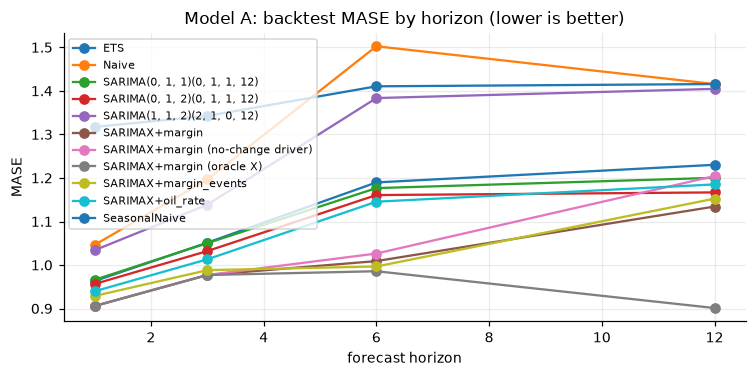

In [16]:
res_a = X.cv_a(cfg, R["monthly"])
sum_a = res_a["summary"]
sum_a.to_csv(TAB / "cv_summary_model_a.csv", index=False); res_a["cv"].to_csv(TAB / "cv_forecasts_model_a.csv", index=False)
print("Base SARIMA order chosen by Stage 1 (lowest mean MASE):", res_a["base_order"])
piv_a = sum_a.pivot_table(index="model", columns="h", values=["MASE", "sMAPE", "coverage95"])
display(piv_a.sort_values(("MASE", 1)).round(3))
display(sum_a.pivot_table(index="model", columns="h", values=["MAE", "RMSE"]).round(0))
P.cv_error_by_h(sum_a, "MASE", "Model A: backtest MASE by horizon (lower is better)", "10_cv_mase_model_a");
plt.show()

In [17]:
def dm_table(cv, ref, others, horizons):
    rows = []
    for other in others:
        for h in horizons:
            a = cv[(cv.model == other) & (cv.h == h)].set_index("origin")
            b = cv[(cv.model == ref) & (cv.h == h)].set_index("origin")
            j = a.join(b, rsuffix="_ref", how="inner")
            st, pv = E.diebold_mariano((j.actual - j.pred).values, (j.actual_ref - j.pred_ref).values, h)
            rows.append({"model": other, "vs": ref, "h": h, "DM_stat": st, "p_value": pv,
                         "MAE_model": (j.actual - j.pred).abs().mean(), "MAE_ref": (j.actual_ref - j.pred_ref).abs().mean()})
    return pd.DataFrame(rows)

base_a = "SARIMA" + X._name(*res_a["base_order"])
dm_a = dm_table(res_a["cv"], base_a, [f"SARIMAX+{k}" for k in cfg["model_a"]["exog_sets"]]
                + ["SARIMAX+margin (no-change driver)", "SARIMAX+margin (oracle X)"], cfg["model_a"]["horizons"])
display(dm_a.round(3)); dm_a.to_csv(TAB / "dm_tests_model_a.csv", index=False)

,model,vs,h,DM_stat,p_value,MAE_model,MAE_ref
0,SARIMAX+oil_rate,"SARIMA(0, 1, 2)(0, 1, 1, 12)",1,-1.739,0.087,74.12,75.48
1,SARIMAX+oil_rate,"SARIMA(0, 1, 2)(0, 1, 1, 12)",3,-2.448,0.017,79.45,81.04
2,SARIMAX+oil_rate,"SARIMA(0, 1, 2)(0, 1, 1, 12)",6,-0.97,0.336,89.75,91
3,SARIMAX+oil_rate,"SARIMA(0, 1, 2)(0, 1, 1, 12)",12,1.496,0.14,93.02,91.66
4,SARIMAX+margin,"SARIMA(0, 1, 2)(0, 1, 1, 12)",1,-0.577,0.566,71.66,75.48
5,SARIMAX+margin,"SARIMA(0, 1, 2)(0, 1, 1, 12)",3,-0.893,0.375,77.25,81.04
6,SARIMAX+margin,"SARIMA(0, 1, 2)(0, 1, 1, 12)",6,-0.892,0.376,78.73,91
7,SARIMAX+margin,"SARIMA(0, 1, 2)(0, 1, 1, 12)",12,-0.521,0.604,88.43,91.66
8,SARIMAX+margin_events,"SARIMA(0, 1, 2)(0, 1, 1, 12)",1,-0.043,0.966,73.43,75.48
9,SARIMAX+margin_events,"SARIMA(0, 1, 2)(0, 1, 1, 12)",3,-0.712,0.479,78.15,81.04


**Diebold–Mariano test.** H0: the two models are equally accurate (squared error). A negative statistic means the SARIMAX model has smaller errors. p < 0.05 means the difference is unlikely to be luck. We use the Harvey–Leybourne–Newbold small-sample correction, because with about 60 origins small differences in MASE are often not significant.


**Reading the Model A backtest** (68 forecast origins, Dec 2020 → Jul 2026, MAE in thousand tonnes)

* **Why is MASE above 1 for most models?** It is not a failure. The MASE denominator is the seasonal-naive error *inside the training window*, which includes the calm, low-volume 2011–2020 years. The test period (2021–26) has record volumes and the 2021–22 price shock, so errors are naturally bigger. What matters is the **ranking**: seasonal naive scores 1.32–1.42 at every horizon, and everything below that is genuine skill.
* **Stage 1 (no drivers).** The best SARIMA is **(0,1,2)(0,1,1)₁₂** (mean MASE ≈ 1.08). It beats ETS, naive and seasonal naive at 3–12 months. `auto_arima`'s stepwise pick (1,1,2)(2,1,0)₁₂ is the worst SARIMA (≈ 1.24), which confirms the section 5 grid.
* **Stage 2: the Model B → Model A link.**

  | added to SARIMA(0,1,2)(0,1,1)₁₂ | MAE h=1 | h=3 | h=6 | h=12 | mean MASE |
  |---|---|---|---|---|---|
  | nothing | 75 | 81 | 91 | 92 | 1.079 |
  | oil rate (lag 2) | 74 | 79 | 90 | 93 | 1.071 |
  | **import margin (lag 3)** | **72** | **77** | **79** | **88** | **1.007** |
  | margin + COVID/Ukraine dummies | 73 | 78 | 78 | 90 | 1.017 |

  * The **plain oil rate** helps slightly at 1–3 months. The Diebold–Mariano test is significant at h = 3 (p ≈ 0.02), but the oil rate makes the 12-month forecast a little worse.
  * The **import margin**, which *contains* the oil rate, is the best model at every horizon: MAE is 4–13% lower than SARIMA, with the biggest gain at 6 months. **But** the Diebold–Mariano p-values are 0.38–0.60. With about 60 test months we cannot rule out that the gain is luck. The honest statement is: *consistent improvement in the right direction, not statistically proven.*
  * **How the driver is forecast matters.** At 12 months the margin model scores MASE 1.13 with an AR(1) driver, 1.20 with a no-change driver, and **0.90 with the true future margin** (oracle). A perfect price outlook would cut the 12-month error by about 23% (MAE 71 vs 92 kt). This quantifies what a better margin forecast is worth.
  * **COVID and Ukraine dummies add nothing**: their effect on imports already shows up in the margin. They are dropped.
* **Interval coverage** is 0.87–0.92 instead of 0.95 at 1–6 months. The intervals are a little too narrow, because model intervals ignore parameter and driver uncertainty, and the residuals have fat tails (section 7).


### 6.2 Model B backtest

Base ARIMA order chosen by Stage 1: (1, 1, 1)


MASE             coverage95             sMAPE            
h                             1     5     20         1     5     20    1     5     20
model                                                                                
ARIMAX(0, 1, 0)+cbot_brent 0.922 1.994 4.527      0.967 0.973  0.94 0.755 1.642 3.667
ARIMAX(1, 1, 1)+cbot_brent 0.922 1.998 4.546      0.967 0.973  0.94 0.755 1.645 3.681
ARIMAX(1, 1, 1)+full       0.923  1.99 4.557       0.96 0.967  0.94 0.756  1.64  3.69
ARIMAX(0, 1, 0)+full       0.925 1.999 4.528       0.96 0.973 0.933 0.758 1.646 3.668
ARIMA(0, 1, 0)             1.022 2.005 4.546      0.967 0.987 0.947 0.833 1.647 3.684
Naive                      1.022 2.005 4.546      0.967 0.987 0.947 0.833 1.647 3.684
ARIMA(1, 1, 1)             1.025 1.985 4.555      0.967 0.993  0.96 0.837  1.63 3.688
ETS                        1.026 1.975 4.641      0.967 0.993  0.96 0.838 1.625 3.752
ARIMA(2, 1, 1)             1.026 1.988 4.558      0.967 0.993  0.96 0.838 1.633  3.69

MAE              RMSE            
h                            1     5     20    1     5     20
model                                                        
ARIMA(0, 1, 0)             9.86 19.38 43.76 15.23 28.16 67.57
ARIMA(1, 1, 1)             9.88 19.19 43.84 15.12 27.68 67.52
ARIMA(2, 1, 1)              9.9 19.23 43.88 15.14 27.75 67.52
ARIMAX(0, 1, 0)+cbot_brent 8.89  19.3 43.58 13.66 28.08 67.58
ARIMAX(0, 1, 0)+full       8.93 19.35 43.59 13.69 28.13 67.61
ARIMAX(1, 1, 1)+cbot_brent  8.9 19.33 43.77 13.66 28.12 67.65
ARIMAX(1, 1, 1)+full        8.9 19.26 43.88 13.67 28.07 67.72
ETS                         9.9  19.1 44.68 15.11 27.37 67.85
Naive                      9.86 19.38 43.76 15.23 28.16 67.57

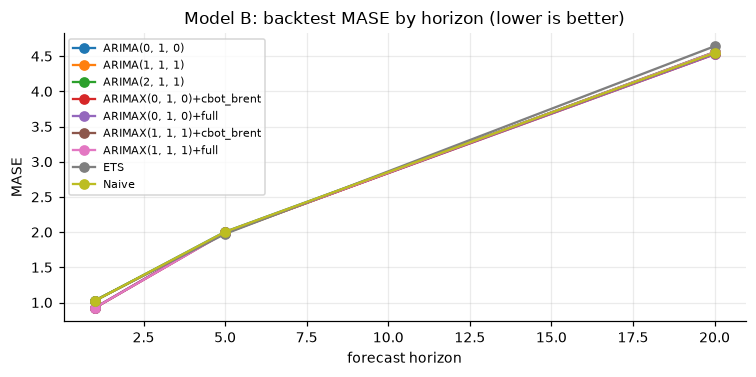

,model,vs,h,DM_stat,p_value,MAE_model,MAE_ref
0,"ARIMAX(0, 1, 0)+cbot_brent",Naive,1,-2.71,0.008,8.895,9.857
1,"ARIMAX(0, 1, 0)+cbot_brent",Naive,5,-0.164,0.87,19.3,19.38
2,"ARIMAX(0, 1, 0)+cbot_brent",Naive,20,0.027,0.979,43.58,43.76
3,"ARIMAX(1, 1, 1)+cbot_brent",Naive,1,-2.72,0.007,8.895,9.857
4,"ARIMAX(1, 1, 1)+cbot_brent",Naive,5,-0.075,0.94,19.33,19.38
5,"ARIMAX(1, 1, 1)+cbot_brent",Naive,20,0.141,0.888,43.77,43.76
6,"ARIMAX(1, 1, 1)+full",Naive,1,-2.666,0.009,8.904,9.857
7,"ARIMAX(1, 1, 1)+full",Naive,5,-0.179,0.858,19.26,19.38
8,"ARIMAX(1, 1, 1)+full",Naive,20,0.258,0.797,43.88,43.76
9,"ARIMAX(0, 1, 0)+full",Naive,1,-2.665,0.009,8.928,9.857


In [18]:
res_b = X.cv_b(cfg, R["daily"])
sum_b = res_b["summary"]
sum_b.to_csv(TAB / "cv_summary_model_b.csv", index=False); res_b["cv"].to_csv(TAB / "cv_forecasts_model_b.csv", index=False)
print("Base ARIMA order chosen by Stage 1:", res_b["base_order"])
display(sum_b.pivot_table(index="model", columns="h", values=["MASE", "sMAPE", "coverage95"]).sort_values(("MASE", 1)).round(3))
display(sum_b.pivot_table(index="model", columns="h", values=["MAE", "RMSE"]).round(2))
P.cv_error_by_h(sum_b, "MASE", "Model B: backtest MASE by horizon (lower is better)", "11_cv_mase_model_b");
plt.show()
exog_models_b = [mm for mm in sum_b.model.unique() if mm.startswith("ARIMAX")]
dm_b = dm_table(res_b["cv"], "Naive", exog_models_b + [f"ARIMA{res_b['base_order']}"], cfg["model_b"]["horizons"])
display(dm_b.round(3)); dm_b.to_csv(TAB / "dm_tests_model_b.csv", index=False)


**Reading the Model B backtest** (150 forecast origins, 5 trading days apart, about Nov 2023 → Oct 2026; MAE in Rs per 10 kg)

* **Without drivers nothing beats the random walk.** ARIMA(1,1,1), ARIMA(2,1,1) and ETS all score MASE ≈ 1.02–1.03 at 1 day, the same as the naive forecast. On its own the Indore price behaves like a random walk, as efficient-market reasoning predicts.
* **With yesterday's CBOT and Brent:** the 1-day MAE falls from **9.9 to 8.9 Rs/10 kg (−10%)** and RMSE from 15.2 to 13.7. The Diebold–Mariano test vs naive gives **p ≈ 0.008: a significant improvement.**
* **At 5 and 20 days there is no gain** (DM p ≈ 0.87–0.98). That is exactly what the leak-free design should show: after day 1 the drivers themselves are only no-change forecasts, so they carry no new information. A model that "improved" 20-day forecasts with a 1-day-lagged driver would be leaking future data.
* Adding USD/INR, duty and the Ukraine dummy (`full`) does not help, and the AR/MA terms do not help either. The rule (lowest mean MASE) picks the **simplest model: ARIMAX(0,1,0) + CBOT + Brent**.
* **Interval coverage 0.94–0.97:** the 95% intervals are well calibrated on average.
* MASE ≈ 4.5 at 20 days means the 20-day error is about 4.5 times the typical 1-day naive error. That is normal for a random-walk-like price, whose uncertainty grows roughly with √h.


## 7. Final models: parameter tables and residual diagnostics

**Why diagnostics?** A SARIMAX is only trustworthy if its residuals look like **white noise**. If they do not, there is structure the model missed and the intervals are wrong. We check:
* **Ljung–Box** (H0: no autocorrelation up to lag k). We want p > 0.05.
* **Jarque–Bera** (H0: normal residuals). The intervals assume normality.
* **ARCH-LM and break-variance** (H0: constant variance, i.e. no heteroscedasticity).
* **OLS-CUSUM** (H0: no structural break in the mean of the residuals).

The final model is refitted on **all** data with the specification that won the backtest.

mean MASE over horizons 1/3/6/12:


,mean MASE
model,
SARIMAX+margin,1.007
SARIMAX+margin_events,1.017
SARIMAX+oil_rate,1.071
"SARIMA(0, 1, 2)(0, 1, 1, 12)",1.079
"SARIMA(0, 1, 1)(0, 1, 1, 12)",1.098
"SARIMA(1, 1, 2)(2, 1, 0, 12)",1.24


SARIMAX(0, 1, 2)(0, 1, 1, 12) + margin


,coef,std_err,z,p_value,ci_low,ci_high
margin_lag3,285.6,70.18,4.069,0,148,423.1
ma.L1,-0.5872,0.0746,-7.87,0,-0.7334,-0.441
ma.L2,-0.1883,0.0747,-2.522,0.0117,-0.3346,-0.042
ma.S.L12,-1,0.0932,-10.73,0,-1.183,-0.8173
sigma2,"4,843",0,2.494e+08,0,"4,843","4,843"


AIC 2025.3  BIC 2041.1  n = 188


,test,H0,stat,p_value,reject_at_5%
0,Ljung-Box lag 12,no autocorrelation,11.67,0.4722,False
1,Ljung-Box lag 24,no autocorrelation,27.44,0.2845,False
2,Jarque-Bera,residuals normal,18.18,0.0001,True
3,ARCH-LM,constant variance (no ARCH),6.662,0.8791,False
4,Break-variance (1st vs last third),equal variance,1.678,0.0509,False
5,OLS-CUSUM,no structural break,0.7772,0.5816,False


largest residuals (thousand tonnes):


month
2015-12-01   326
2021-11-01   205
2021-10-01   192
2015-08-01   160
2021-01-01   159
dtype: float64

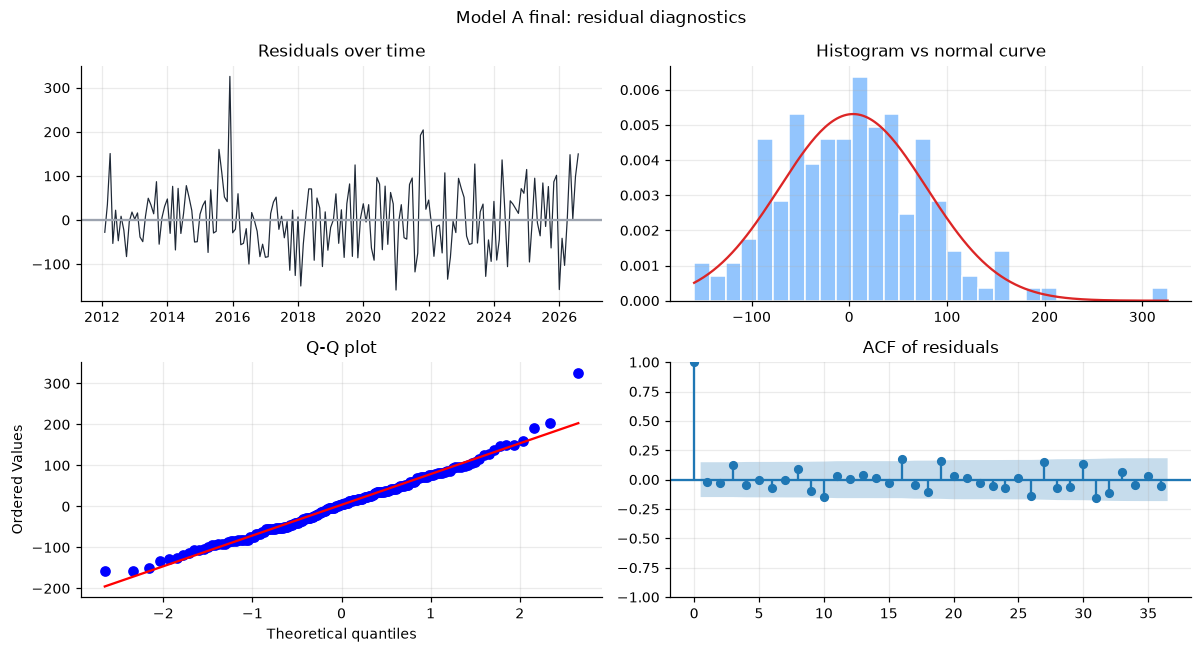

In [19]:
# Selection rule fixed BEFORE looking at the final forecast: lowest MASE averaged over the 4 horizons,
# among models we could actually run in real time (oracle and no-change-driver variants excluded).
real = sum_a[~sum_a.model.str.contains("oracle|no-change") & sum_a.model.str.startswith("SARIMA")]
rank_a = real.groupby("model").MASE.mean().sort_values()
print("mean MASE over horizons 1/3/6/12:"); display(rank_a.round(3).to_frame("mean MASE"))
best_a = rank_a.index[0]
FINAL_A_SET = best_a.split("+", 1)[1] if best_a.startswith("SARIMAX+") else None
o_a, so_a = res_a["base_order"]
lags_a = cfg["model_a"]["exog_sets"].get(FINAL_A_SET) if FINAL_A_SET else None
y_full = X.target_a(cfg, R["monthly"])
steps_a = cfg["model_a"]["forecast_steps"]
METH_A = cfg["model_a"].get("exog_forecast", {})
TR_A = cfg["model_a"]["transform"]
final_a, fc_a, _ = X.fit_and_forecast(y_full, o_a, so_a, lags_a, Xa_raw, "MS", steps_a, transform=TR_A, methods=METH_A)
print(final_a.name, "+", FINAL_A_SET or "no exog")
pt_a = M.parameter_table(final_a.res); display(pt_a.round(4)); pt_a.to_csv(TAB / "final_params_model_a.csv")
print(f"AIC {final_a.res.aic:.1f}  BIC {final_a.res.bic:.1f}  n = {final_a.res.nobs}")
burn_a = 13          # first d + s*D residuals are start-up values of the filter
diag_a = E.residual_diagnostics(final_a.res, lags=[12, 24], burn=burn_a)
display(diag_a.round(4)); diag_a.to_csv(TAB / "diagnostics_model_a.csv", index=False)
P.residual_plot(final_a.res, "Model A final: residual diagnostics", "12_resid_model_a", burn=burn_a, lags=36)
r_a = pd.Series(final_a.res.resid).iloc[burn_a:]
print("largest residuals (thousand tonnes):"); display(r_a.abs().sort_values(ascending=False).head(5).round(0))
plt.show()


**Final Model A: SARIMAX(0,1,2)(0,1,1)₁₂ + import margin (lag 3)**, fitted on Jan 2011 to Aug 2026, in thousand tonnes.

* **Margin coefficient ≈ 286 kt per unit of log-margin (p < 0.001, 95% CI ≈ 148–423).** A domestic price 10% higher relative to landed cost adds about **27 thousand tonnes** of imports three months later, roughly 6% of an average month. The sign, size and lag all make economic sense.
* The MA terms (−0.59, −0.19) are significant. The seasonal MA sits at **−1**, the boundary discussed in section 3.1 (deterministic seasonality), so its standard error and the σ² standard error are not meaningful.
* **Ljung–Box p ≈ 0.47 (lag 12) and 0.28 (lag 24): no autocorrelation is left.** The model has captured the dynamics.
* **ARCH-LM p ≈ 0.88:** no volatility clustering. The break-variance test is borderline (p ≈ 0.05): residuals are a little larger in the last third, when volumes are larger.
* **Jarque–Bera rejects normality** because of a few large surprises: Dec 2015 (+326 kt, a record month), Oct–Nov 2021 (the surge after the Oct-2021 duty cut, plus the flagged Oct-2021 weight), Aug 2015 and Jan 2021. The intervals assume normal errors, so tail risk is under-stated. That explains the 0.87–0.92 coverage.
* **OLS-CUSUM p ≈ 0.58: no structural break** in the residuals. The 2014–15 level shift is absorbed by differencing.


mean MASE over horizons 1/5/20:


,mean MASE
model,
"ARIMAX(0, 1, 0)+cbot_brent",2.481
"ARIMAX(0, 1, 0)+full",2.484
"ARIMAX(1, 1, 1)+cbot_brent",2.489
"ARIMAX(1, 1, 1)+full",2.49
"ARIMA(1, 1, 1)",2.521
"ARIMA(0, 1, 0)",2.524
Naive,2.524
"ARIMA(2, 1, 1)",2.524
ETS,2.547


ARIMAX(0, 1, 0) + cbot_brent


,coef,std_err,z,p_value,ci_low,ci_high
cbot_soyoil_lag1,0.2543,0.0125,20.33,0,0.2298,0.2789
brent_lag1,0.0246,0.0116,2.119,0.0341,0.0018,0.0474
sigma2,0.0001,0,76.47,0,0.0001,0.0001


AIC -10491.5  BIC -10475.3  n = 1663


,test,H0,stat,p_value,reject_at_5%
0,Ljung-Box lag 5,no autocorrelation,24.55,0.0002,True
1,Ljung-Box lag 10,no autocorrelation,43.02,0,True
2,Ljung-Box lag 20,no autocorrelation,47.63,0.0005,True
3,Jarque-Bera,residuals normal,1.153e+04,0,True
4,ARCH-LM,constant variance (no ARCH),40,0.0001,True
5,Break-variance (1st vs last third),equal variance,0.4198,0,True
6,OLS-CUSUM,no structural break,0.7905,0.5597,False


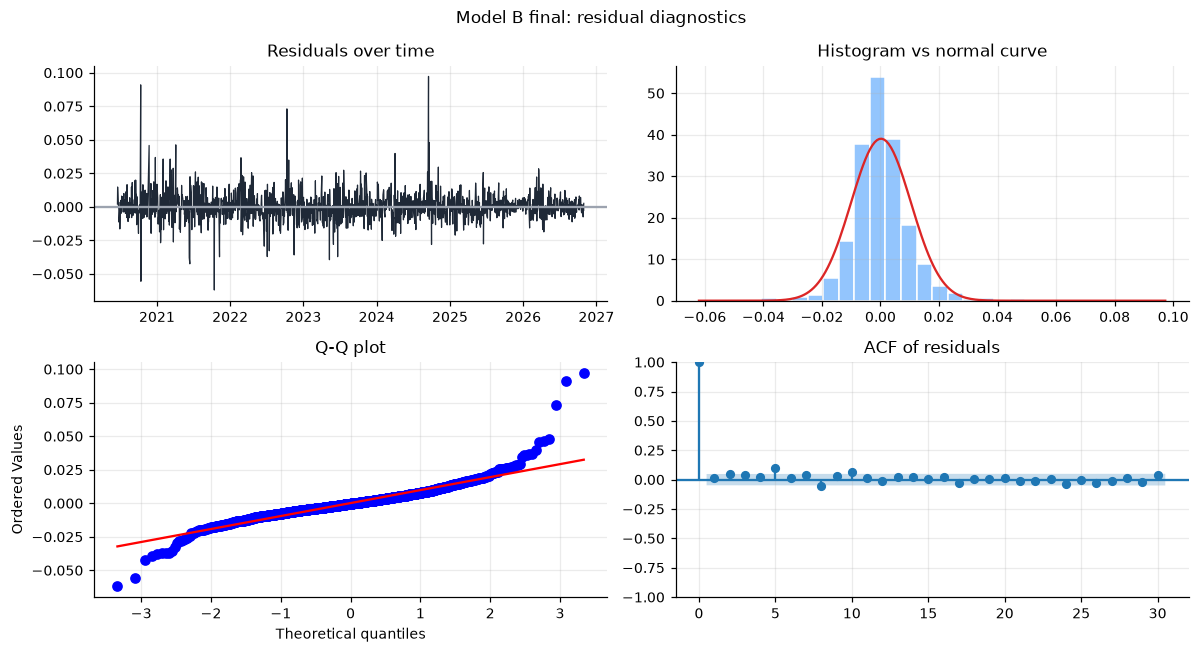

In [20]:
import re
real_b = sum_b[sum_b.model.str.startswith("ARIMAX")]
rank_b = sum_b.groupby("model").MASE.mean().sort_values()
print("mean MASE over horizons 1/5/20:"); display(rank_b.round(3).to_frame("mean MASE"))
best_b = real_b.groupby("model").MASE.mean().idxmin()
FINAL_B_ORDER = tuple(int(v) for v in re.findall(r"\d+", best_b.split("+")[0]))
FINAL_B_SET = best_b.split("+", 1)[1]
lags_b = cfg["model_b"]["exog_sets"][FINAL_B_SET]
yb_full = X.target_b(cfg, R["daily"])
steps_b = cfg["model_b"]["forecast_steps"]
final_b, fc_b, _ = X.fit_and_forecast(yb_full, FINAL_B_ORDER, (0, 0, 0, 0), lags_b, Xb_raw, "B", steps_b)
print(final_b.name, "+", FINAL_B_SET)
pt_b = M.parameter_table(final_b.res); display(pt_b.round(4)); pt_b.to_csv(TAB / "final_params_model_b.csv")
print(f"AIC {final_b.res.aic:.1f}  BIC {final_b.res.bic:.1f}  n = {final_b.res.nobs}")
diag_b = E.residual_diagnostics(final_b.res, lags=[5, 10, 20], burn=1)
display(diag_b.round(4)); diag_b.to_csv(TAB / "diagnostics_model_b.csv", index=False)
P.residual_plot(final_b.res, "Model B final: residual diagnostics", "13_resid_model_b", burn=1, lags=30)
plt.show()


**Final Model B: ARIMAX(0,1,0) on log price + CBOT soybean oil (lag 1) + Brent (lag 1).**

* **CBOT elasticity ≈ 0.25 (95% CI 0.23–0.28):** a 1% move in Chicago soybean oil moves the Indore rate about 0.25% the next day. Pass-through is partial because the landed cost also depends on duty, freight and the rupee, and the domestic crop matters too.
* **Brent ≈ 0.025 (p ≈ 0.03):** small but significant, through the bio-diesel link between crude oil and vegetable oil.
* **The diagnostics are imperfect, and we say so:** Ljung–Box rejects (small autocorrelation left at weekly lags, consistent with the Monday effect), Jarque–Bera strongly rejects (fat tails: days like the +10% duty jump), and ARCH-LM rejects (**volatility clustering**: calm and turbulent periods alternate).
* **Consequence:** the point forecast is fine, but the interval width is "average". It is too narrow in turbulent periods and too wide in calm ones, which averages out to good coverage (0.94–0.97 in the backtest). The textbook fix is an **ARIMA–GARCH** model (future work). Adding AR/MA terms did not improve out-of-sample accuracy, so we keep the parsimonious model.
* OLS-CUSUM finds no structural break.


## 8. Forecasts with 95% intervals and scenario tests

**Scenarios** change only the *future* path of a driver. The fitted coefficients stay the same:
* **Duty cut:** effective duty on crude soybean oil −5.5 points (16.5% → 11%, the size of the Sep-2026 cut). For Model A this raises the import margin by log((1+d)/(1+d−0.055)).
* **Price shock ±10%:** for Model A the domestic oil rate is 10% higher or lower (margin ± log 1.1). For Model B CBOT soybean oil is 10% higher or lower from tomorrow.

The scenario model for Model A is **SARIMAX + margin**, because it is the specification whose coefficient has an economic meaning. This is stated in the plot title.

margin coefficient = 285.6 kt per unit of log-margin (p = 0.000), i.e. a margin 10% higher adds about 27.2 thousand tonnes of imports 3 months later
Model A forecast, thousand tonnes (SARIMAX(0, 1, 2)(0, 1, 1, 12) + margin):


,mean,lower,upper,scenario: duty cut -5.5 pts,scenario: oil rate +10%,scenario: oil rate -10%
date,,,,,,
Sep 2026,510,370,651,510,510,510
Oct 2026,481,328,633,481,481,481
Nov 2026,439,284,595,439,439,439
Dec 2026,448,289,606,461,475,417
Jan 2027,457,295,619,471,484,427
Feb 2027,459,294,624,473,486,429
Mar 2027,455,287,623,469,482,425
Apr 2027,477,307,648,491,505,447
May 2027,506,332,680,520,533,476


12-month total: 5.91 Mt (95% band per month shown above); previous 12 months (actual): 5.56 Mt


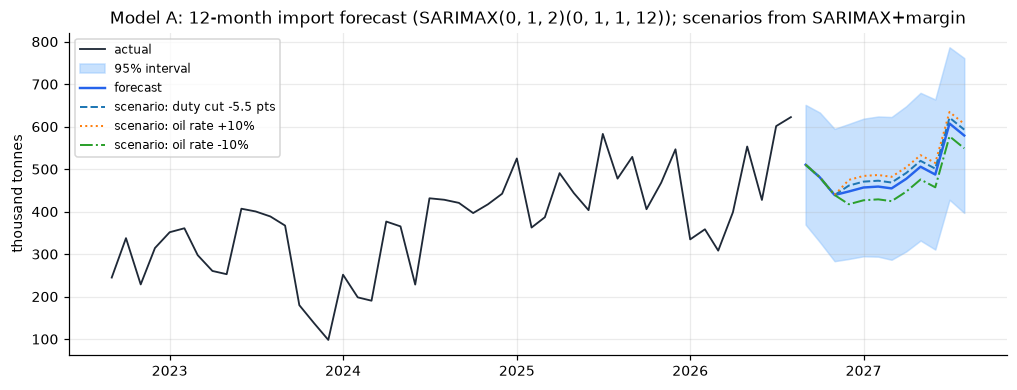

In [21]:
# ---- Model A: forecast with the backtest winner; scenarios with SARIMAX+margin ----
d_now = Xa_raw.duty.iloc[-1]
dcut = np.log((1 + d_now / 100) / (1 + (d_now - cfg["scenarios"]["duty_cut_points"]) / 100))
scen_a = {"scenario: duty cut -5.5 pts": {"margin": lambda s: s + dcut},
          "scenario: oil rate +10%": {"margin": lambda s: s + np.log(1.10)},
          "scenario: oil rate -10%": {"margin": lambda s: s + np.log(0.90)}}
mod_ma, fc_ma, sc_a = X.fit_and_forecast(y_full, o_a, so_a, cfg["model_a"]["exog_sets"]["margin"], Xa_raw, "MS",
                                         steps_a, transform=TR_A, scenarios=scen_a, methods=METH_A)
b_m = mod_ma.res.params["margin_lag3"]
print(f"margin coefficient = {b_m:,.1f} kt per unit of log-margin (p = {mod_ma.res.pvalues['margin_lag3']:.3f}), "
      f"i.e. a margin 10% higher adds about {b_m * np.log(1.1):,.1f} thousand tonnes of imports 3 months later")
out_a = fc_a.copy()
for k, v in sc_a.items():
    out_a[k] = v
out_a.index.name = "date"
out_a.to_csv(FCD / "model_a_forecast.csv")
pd.DataFrame({"value": y_full}).rename_axis("date").to_csv(FCD / "model_a_history.csv")
show = out_a.round(0); show.index = show.index.strftime("%b %Y")
print(f"Model A forecast, thousand tonnes ({final_a.name} + {FINAL_A_SET or 'no exog'}):"); display(show)
print(f"12-month total: {fc_a['mean'].sum()/1e3:.2f} Mt (95% band per month shown above); "
      f"previous 12 months (actual): {y_full.iloc[-12:].sum()/1e3:.2f} Mt")
P.forecast_plot(y_full, out_a[["mean", "lower", "upper"]],
                f"Model A: 12-month import forecast ({final_a.name}); scenarios from SARIMAX+margin",
                "thousand tonnes", "14_forecast_model_a", tail=48,
                scenarios=sc_a);
plt.show()

duty coefficient in the 'full' model (change in log price per duty point): 0.0033 p = 0.0
Model B forecast, Rs per 10 kg (ARIMAX(0, 1, 0) + cbot_brent), selected days:


,mean,lower,upper,scenario: CBOT soy oil +10%,scenario: CBOT soy oil -10%,scenario: duty cut -5.5 pts (full model)
date,,,,,,
02 Nov 2026,"1,419","1,391","1,447","1,419","1,419","1,394"
06 Nov 2026,"1,419","1,357","1,483","1,454","1,381","1,394"
13 Nov 2026,"1,419","1,332","1,511","1,454","1,381","1,394"
27 Nov 2026,"1,419","1,298","1,551","1,454","1,381","1,394"
11 Dec 2026,"1,419","1,272","1,582","1,454","1,381","1,394"


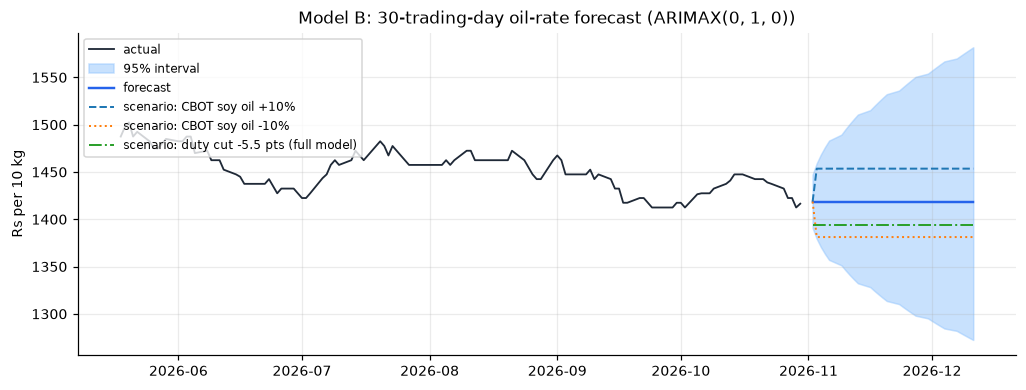

In [22]:
scen_b = {"scenario: CBOT soy oil +10%": {"cbot_soyoil": lambda s: s + np.log(1.10)},
          "scenario: CBOT soy oil -10%": {"cbot_soyoil": lambda s: s + np.log(0.90)}}
_, _, sc_b = X.fit_and_forecast(yb_full, FINAL_B_ORDER, (0, 0, 0, 0), lags_b, Xb_raw, "B", steps_b, scenarios=scen_b)
# the duty-cut scenario needs duty in the model: use the 'full' specification (same order) for it
lags_full = cfg["model_b"]["exog_sets"]["full"]
mod_bf, _, sc_bf = X.fit_and_forecast(yb_full, FINAL_B_ORDER, (0, 0, 0, 0), lags_full, Xb_raw, "B", steps_b,
    scenarios={"scenario: duty cut -5.5 pts (full model)": {"duty": lambda s: s - cfg["scenarios"]["duty_cut_points"]}})
sc_b.update(sc_bf)
print("duty coefficient in the 'full' model (change in log price per duty point):",
      round(mod_bf.res.params["duty_lag0"], 4), "p =", round(mod_bf.res.pvalues["duty_lag0"], 3))
out_b = fc_b.copy()
for k, v in sc_b.items():
    out_b[k] = v
out_b.index.name = "date"
out_b.to_csv(FCD / "model_b_forecast.csv")
pd.DataFrame({"value": yb_full.dropna()}).rename_axis("date").to_csv(FCD / "model_b_history.csv")
show = out_b.round(1).iloc[[0, 4, 9, 19, 29]]; show.index = show.index.strftime("%d %b %Y")
print(f"Model B forecast, Rs per 10 kg ({final_b.name} + {FINAL_B_SET}), selected days:"); display(show)
P.forecast_plot(yb_full, out_b[["mean", "lower", "upper"]], f"Model B: 30-trading-day oil-rate forecast ({final_b.name})",
                "Rs per 10 kg", "15_forecast_model_b", tail=120, scenarios=sc_b);
plt.show()


**Model A: Sep 2026 to Aug 2027** (origin = Aug 2026, the last Comtrade month)
* Central forecast **≈ 5.9 Mt** over 12 months vs 5.56 Mt in the previous 12 months (+6%), continuing the upward trend. The seasonal shape repeats: lowest Nov 2026–Mar 2027 (≈ 440–460 kt/month), highest Jul–Aug 2027 (≈ 580–610 kt). The 95% band is about ±150–180 kt per month.
* **Scenarios** start to bite in **Dec 2026**, because the margin enters with a 3-month lag:
  * duty −5.5 points: about **+14 kt/month (+3%)**. This scenario is effectively the **real 24-Sep-2026 cut** (16.5% → 11%), which happened after our last data month. So the model expects slightly higher imports from December.
  * oil rate +10%: about +27 kt/month. Oil rate −10%: about −30 kt/month.

**Model B: next 30 trading days** (origin = 30 Oct 2026)
* The central forecast is **flat at ≈ Rs 1,419 / 10 kg**. For a random-walk-like price the best forecast is today's price plus the reaction to the latest CBOT and Brent move. The 95% band widens from about ±Rs 28 (1 day) to about ±Rs 155 (30 days).
* **CBOT ±10%** → about **±Rs 35–38 (±2.5%)** from the second day.
* **A further duty cut of 5.5 points** (11% → 5.5%, hypothetical; the Sep-2026 cut is already in the price) → about **−Rs 25 (−1.8%)**, using the `full` model's duty coefficient (0.0033 per duty point, p < 0.001).


## 9. Conclusion


### Did the exogenous variables help?

| | Model B (daily oil rate) | Model A (monthly imports) |
|---|---|---|
| Driver | CBOT soybean oil + Brent, lag 1 day | import margin = oil rate vs landed cost, lag 3 months |
| Accuracy gain | **−10% MAE at 1 day, significant (DM p ≈ 0.008)** | −4% to −13% MAE at 1–12 months, **not significant** (DM p ≈ 0.4–0.6) |
| Beyond the lag | no gain at 5–20 days | gain shrinks at 12 months; the driver forecast is the bottleneck |
| Coefficient | elasticity 0.25 (strong) | +27 kt per +10% margin (p < 0.001) |

* **The link between the two models works, but through economics, not the raw price.** The lagged monthly oil rate on its own (the direct Model B → Model A link) gives only marginal gains and slightly hurts at 12 months. The oil rate *relative to the landed cost of imported oil* (the import margin) gives the best Model A at every horizon. Importers react to profitability, not to the price level.
* The daily price is nearly a random walk. Outside information gives real skill only for the next day.

### Where the models fail
* **Surprise months:** record or post-policy shipments (Dec 2015, Oct–Nov 2021). The model cannot foresee a sudden policy change or a buying spree.
* **12-month horizon:** accuracy depends on how well the margin can be forecast. The oracle run shows up to 23% lower error with perfect foresight of the driver.
* **Daily model:** beyond one day it is no better than "price stays the same". Fat tails and volatility clusters make the intervals too narrow on shock days.
* Model A's 95% intervals cover about 87–92% of actual values, so they are slightly too narrow.

### Limitations
* **Data:** two Comtrade weights imputed, about 25 months with Comtrade-*estimated* weights, Oct 2021 suspicious, and Comtrade figures get revised. HS 1507 mixes crude and refined oil, while the duty variable is for crude oil only. SOPA has long gaps before mid-2020 (so Model B starts in 2020) and irregular Saturdays.
* **Sample size:** 188 months and about 68 test origins give low statistical power. Real gains of 5–10% are hard to prove significant.
* **The margin is simplified:** it ignores freight, refining cost, and competition from **palm and sunflower oil** (India's main substitutes), and it uses the CBOT price rather than the actual Argentine or Brazilian FOB price India pays.
* **Duty dates** come from notifications and news reports. The Aug-2017 change is "medium" confidence (date not found in an official source; supported by a price jump).
* **Linear Gaussian models:** no GARCH volatility, no regime switching.
* The Model A forecast is made from Aug 2026 and does not use the Sep–Oct 2026 prices already known today.

### Future work
Palm oil (Bursa Malaysia) and sunflower oil prices; India's soybean crop and crush estimates (SOPA); freight; splitting crude (HS 150710) and refined (HS 150790) imports; ARIMA–GARCH for Model B; a Monday dummy; Fourier or dummy seasonality for Model A; forecast combinations. Re-run monthly as new Comtrade and SOPA data arrive (`config.yaml` → change `end`).
